<div align="center">

<img src="https://cdn.pixabay.com/photo/2015/04/09/16/39/indonesia-714747_960_720.png" width="150" height="130" />

# Peta Karhutla Indonesia
### Choropleth, Peta Titik, dan Peta Interaktif

**Nama:** Adinda Adelia Futri
**NIM:** 52250055
**Mata Kuliah:** Analisis Data Spasial

</div>

---

## Pendahuluan

Notebook ini memetakan **luas kebakaran hutan dan lahan (karhutla) per provinsi di Indonesia pada periode 2018–2026**, berdasarkan file `luas-karhutla-provinsi.xlsx`. Alur kerjanya mengikuti modul praktikum GeoPandas, yaitu membaca data, menyamakan sistem koordinat (CRS), melakukan normalisasi, menjalankan operasi spasial, lalu menyusun peta.

> **Tujuan:** Mengetahui **di mana** karhutla paling luas, **seberapa parah** dibandingkan luas wilayahnya, dan **bagaimana perubahannya dari tahun ke tahun**, sehingga wilayah dan tahun yang paling terdampak dapat terlihat dengan jelas.

### Daftar Isi

| No | Bagian |
|----|--------|
| 1 | Penjelasan notebook dan import library |
| 2 | Membaca dan membersihkan data karhutla |
| 3 | Membaca batas provinsi dan memeriksa CRS |
| 4 | Menyamakan wilayah (pemekaran Papua) |
| 5 | Join data ke peta, reproyeksi, dan normalisasi |
| 6 | Operasi spasial: buffer, dissolve, dan spatial join |
| 7 | Peta choropleth luas karhutla |
| 8 | Peta intensitas karhutla (normalisasi ha/km²) |
| 9 | Perbandingan antar tahun |
| 10 | Peta choropleth interaktif luas karhutla per provinsi |
| 11 | Peta titik karhutla (*proportional symbol*) |
| 12 | Peta titik interaktif karhutla per provinsi |
| 13 | Peta titik panas FIRMS 2026 |
| 14 | Peta choropleth jumlah titik panas per provinsi |
| 15 | Kesimpulan |

Setiap peta disertai penjelasan mengenai **apa yang ditampilkan**, **tujuannya**, dan **temuan** yang dihitung otomatis dari data. Temuan tersebut ikut berubah jika nilai `TAHUN` diganti.

> **Catatan:** Dataset hanya berisi angka luas per provinsi. Karena itu, setiap "titik" pada peta titik merepresentasikan satu provinsi, ditempatkan di pusat wilayahnya, dengan ukuran dan warna yang mengikuti luas karhutla.

---

## 1. Penjelasan Notebook dan Import Library

Sel berikut memuat seluruh library yang digunakan dalam notebook:

- **`pandas` dan `numpy`** untuk pengolahan data
- **`geopandas`** untuk data spasial
- **`matplotlib`** untuk peta statis
- **`IPython.display`** untuk menampilkan teks temuan

Variabel `TAHUN` menentukan tahun yang ditampilkan pada peta tunggal.

---

*Dokumen ini disusun sebagai bagian dari tugas mata kuliah Analisis Data Spasial.*

---
## Sumber Data

- **Luas karhutla per provinsi, 2018–2026 (`luas-karhutla-provinsi.xlsx`):** SIPONGI KEMENHUT, Indikasi Luas Kebakaran, https://sipongi.gakkum.kehutanan.go.id/indikasi-luas-kebakaran (unduh XLSX, Semua Provinsi).
  Data ini wajib dicantumkan sumbernya sebagai **SIPONGI KEMENHUT**.
  > **Catatan periode:** data tahun 2026 hanya mencakup Januari–Juli 2026, sehingga belum satu tahun penuh dan perlu hati-hati saat dibandingkan dengan tahun lain.
- **Batas provinsi (`indonesia-prov.geojson`):** https://raw.githubusercontent.com/ans-4175/peta-indonesia-geojson/master/indonesia-prov.geojson. Sumber di dalam file (kolom `SUMBER`): Peta Dasar BAKOSURTANAL skala 1:250.000 (29 provinsi) dan Batas Provinsi Desember 2019 Dukcapil (5 provinsi).
- **Titik panas FIRMS (`DL_FIRE_SV-C2_839983`):** https://firms.modaps.eosdis.nasa.gov/download/ (VIIRS SNPP, 1 Jan – 2 Nov 2026)

**Sistem koordinat yang dipakai:** EPSG:4326 (WGS84) untuk data asli dan peta interaktif, serta EPSG:3857 (Web Mercator) untuk analisis dan peta statis karena satuannya meter.

In [1]:
# Catatan: bagian kode ini digunakan untuk memuat library yang dipakai di seluruh notebook (pandas dan numpy untuk data,
# geopandas untuk data spasial, matplotlib untuk peta, IPython.display untuk teks temuan) serta menetapkan tahun yang dipetakan (TAHUN).
import os, urllib.request
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from IPython.display import Markdown, display
pd.options.display.float_format = '{:,.2f}'.format

# Ubah tahun yang ingin dipetakan di sini (2018 - 2026)
TAHUN = 2023

In [2]:
# Catatan: bagian kode ini menyiapkan elemen peta statis: sumbu bujur/lintang dalam derajat (BT/BB, LU/LS),
# legenda kelas yang batasnya dihitung dari data (sesuai dataset), serta fungsi pembantu untuk keduanya.
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

R_WM = 6378137.0   # jari-jari bumi pada EPSG:3857 (meter)
def _lon2x(lon): return np.radians(lon) * R_WM
def _lat2y(lat): return R_WM * np.log(np.tan(np.pi / 4 + np.radians(lat) / 2))
def _x2lon(x): return np.degrees(x / R_WM)
def _y2lat(y): return np.degrees(2 * np.arctan(np.exp(y / R_WM)) - np.pi / 2)

def _deg_bujur(v):
    v = round(float(v), 6)
    arah = 'BT' if v > 0 else ('BB' if v < 0 else '')
    return f"{abs(v):.0f}°{arah}"

def _deg_lintang(v):
    v = round(float(v), 6)
    arah = 'LU' if v > 0 else ('LS' if v < 0 else '')
    return f"{abs(v):.0f}°{arah}"

def tambah_koordinat(ax, langkah=5, meter=True, label=True, ukuran=9):
    # Sumbu dalam derajat. meter=True jika data berada pada EPSG:3857, False jika EPSG:4326.
    x0, x1 = sorted(ax.get_xlim()); y0, y1 = sorted(ax.get_ylim())
    if meter:
        bujur_min, bujur_max, lintang_min, lintang_max = _x2lon(x0), _x2lon(x1), _y2lat(y0), _y2lat(y1)
    else:
        bujur_min, bujur_max, lintang_min, lintang_max = x0, x1, y0, y1
    bujur = np.arange(np.ceil(bujur_min / langkah) * langkah, bujur_max + 1e-9, langkah)
    lintang = np.arange(np.ceil(lintang_min / langkah) * langkah, lintang_max + 1e-9, langkah)
    ax.set_xticks(_lon2x(bujur) if meter else bujur)
    ax.set_yticks(_lat2y(lintang) if meter else lintang)
    if meter:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: _deg_bujur(_x2lon(x))))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: _deg_lintang(_y2lat(y))))
    else:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: _deg_bujur(x)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: _deg_lintang(y)))
    ax.set_facecolor('#dbe9f4')                     # warna laut
    ax.grid(True, color='grey', alpha=0.35, linestyle='--', linewidth=0.5)
    ax.tick_params(labelsize=ukuran)
    if label:
        ax.set_xlabel('Bujur (Longitude)', fontsize=ukuran + 1)
        ax.set_ylabel('Lintang (Latitude)', fontsize=ukuran + 1)

def _batas_kelas(nilai, k=6):
    # Batas atas setiap kelas dihitung dari data (Fisher-Jenks jika mapclassify tersedia, jika tidak quantile)
    try:
        import mapclassify as mc
        if len(nilai) <= 5000:
            return [float(b) for b in mc.FisherJenks(nilai, k=k).bins]
    except ImportError:
        pass
    return [float(b) for b in np.unique(np.quantile(nilai, np.linspace(0, 1, k + 1)[1:]))]

def skala_kelas(nilai, cmap_nama='OrRd', k=6, desimal=0):
    # Mengembalikan colormap diskret, normalisasi, dan daftar legenda berisi rentang nilai dari data.
    v = np.asarray(nilai, dtype=float)
    v = v[np.isfinite(v)]
    vmin, vmax = float(v.min()), float(v.max())
    batas = np.unique(np.r_[vmin - 1e-9, _batas_kelas(v, k)])
    batas[-1] = vmax + 1e-9
    n = len(batas) - 1
    warna = plt.get_cmap(cmap_nama)(np.linspace(0.15, 0.95, n))
    cmap = mcolors.ListedColormap(warna)
    norm = mcolors.BoundaryNorm(batas, n)
    labels = []
    for i in range(n):
        lo = vmin if i == 0 else batas[i]
        hi = vmax if i == n - 1 else batas[i + 1]
        labels.append(f"{rp(lo, desimal)} – {rp(hi, desimal)}")
    handles = [Patch(facecolor=w, edgecolor='grey', label=l) for w, l in zip(warna, labels)]
    return cmap, norm, handles

def tambah_legenda(ax, handles, judul, loc='lower left'):
    return ax.legend(handles=handles, title=judul, loc=loc, fontsize=8, title_fontsize=9,
                     frameon=True, facecolor='white', framealpha=0.95)


---
## 2. Membaca & Membersihkan Data Karhutla
Angka di Excel berformat Indonesia (`1.284,70` = titik sebagai pemisah ribuan, koma sebagai desimal) sehingga terbaca sebagai teks. Kita ubah menjadi angka, lalu buang baris `Total` agar tidak ikut terhitung sebagai provinsi.

In [3]:
# Catatan: bagian kode ini digunakan untuk membaca data karhutla dari Excel, membuang baris Total,
# dan mengubah angka berformat Indonesia (mis. 1.284,70) menjadi bilangan desimal agar dapat dihitung.
df = pd.read_excel('luas-karhutla-provinsi.xlsx')

# Buang baris Total
df.columns = [str(c) for c in df.columns]   # nama kolom tahun dijadikan teks ('2018', '2019', ...)
df = df[df['Provinsi'] != 'Total'].copy()
df['Kode Wilayah'] = df['Kode Wilayah'].astype(int)

# Konversi format angka Indonesia -> float
kolom_tahun = [c for c in df.columns if str(c).isdigit()]
for c in kolom_tahun:
    df[c] = (df[c].astype(str)
                  .str.replace('.', '', regex=False)    # hapus pemisah ribuan
                  .str.replace(',', '.', regex=False)   # koma -> titik desimal
                  .astype(float))

print("Jumlah provinsi:", len(df))
df.head()

Jumlah provinsi: 38


,Kode Wilayah,Provinsi,2018,2019,2020,2021,2022,2023,2024,2025,2026
0,11,Aceh,"1,284.70",730.00,"1,078.00","1,267.00","3,716.00","1,936.86","7,257.35",355.01,"4,070.48"
1,51,Bali,"1,013.76",373.00,29.00,3.00,0.00,"2,011.27",316.36,93.08,108.28
2,19,Bangka Belitung,"2,055.67","4,778.00",576.00,385.00,328.00,"4,752.98","2,915.46",214.71,335.63
3,36,Banten,0.00,9.00,2.00,0.00,0.00,1.01,362.83,4.44,8.28
4,17,Bengkulu,8.82,11.00,221.00,93.00,"1,620.00",75.94,355.05,157.81,125.15


---
## 3. Membaca Batas Provinsi & Memeriksa CRS
Data peta yang dipakai adalah GeoJSON batas provinsi Indonesia (kolom `Propinsi` dan `kode`, sama seperti data di modul). Jika file belum ada di folder, notebook mengunduhnya otomatis.

In [4]:
# Catatan: bagian kode ini digunakan untuk membaca batas provinsi dengan gpd.read_file (mengunduh file jika belum ada),
# memeriksa CRS, dan menyiapkan kode provinsi sebagai kunci penghubung dengan data karhutla.
geo_file = 'indonesia-prov.geojson'
if not os.path.exists(geo_file):
    url = 'https://raw.githubusercontent.com/ans-4175/peta-indonesia-geojson/master/indonesia-prov.geojson'
    urllib.request.urlretrieve(url, geo_file)

gdf = gpd.read_file(geo_file)
print("CRS awal:", gdf.crs)
if gdf.crs is None:
    gdf = gdf.set_crs("EPSG:4326")

# Kode provinsi harus integer agar bisa dicocokkan dengan 'Kode Wilayah'
gdf['kode'] = gdf['kode'].astype(int)
print("Jumlah polygon provinsi:", len(gdf))
gdf.head(3)

CRS awal: EPSG:4326
Jumlah polygon provinsi: 34


,ID,kode,Propinsi,SUMBER,geometry
0,2,52,NUSATENGGARA BARAT,Peta Dasar BAKOSURTANAL Skala 1 : 250.000,"MULTIPOLYGON (((117.6272 -8.5064, 117.6347 -8...."
1,3,75,GORONTALO,Peta Dasar BAKOSURTANAL Skala 1 : 250.000,"POLYGON ((122.18814 1.0453, 122.22627 1.00335,..."
2,4,74,SULAWESI TENGGARA,Peta Dasar BAKOSURTANAL Skala 1 : 250.000,"MULTIPOLYGON (((120.98423 -2.83534, 121.07834 ..."


### Plot cepat batas provinsi
Sebelum analisis dilakukan, batas provinsi ditampilkan langsung untuk memastikan geometri GeoJSON terbaca dengan benar, misalnya tidak ada wilayah yang hilang atau bentuknya rusak. Langkah ini setara dengan `df.plot()` pada modul praktikum.

<class 'geopandas.geodataframe.GeoDataFrame'>


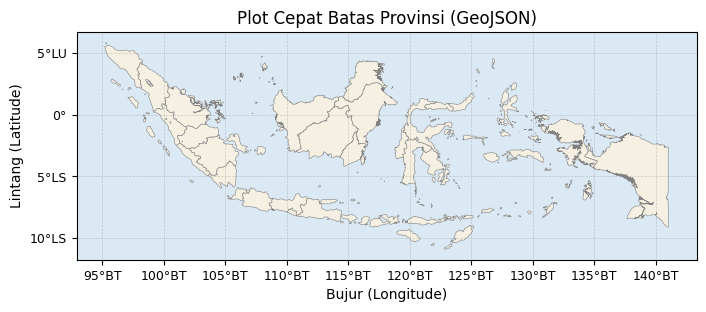

In [5]:
# Catatan: menampilkan seluruh batas provinsi sebagai pemeriksaan awal, dengan sumbu bujur dan lintang.
# print(type(...)) memastikan objek yang dipakai adalah GeoDataFrame, sehingga fungsi spasial dapat digunakan.
print(type(gdf))
fig, ax = plt.subplots(figsize=(8, 5))
gdf.plot(ax=ax, facecolor='#f5f0e1', edgecolor='grey', linewidth=0.4)
ax.set_title('Plot Cepat Batas Provinsi (GeoJSON)')
tambah_koordinat(ax, langkah=5, meter=False)
plt.show()


### Sistem Koordinat (CRS): Lat/Lon dan Meter

Setiap GeoDataFrame memiliki **CRS** (*Coordinate Reference System*) yang menentukan satuan koordinatnya.

- **`EPSG:4326` (WGS84)** menyimpan lokasi dalam derajat lintang dan bujur (lat/lon). Sistem ini cocok untuk menyimpan dan menampilkan data, tetapi satuannya bukan meter, sehingga **tidak tepat** untuk menghitung luas.
- **`EPSG:3857` (Web Mercator)** menyimpan koordinat dalam meter, sehingga luas dan jarak dapat dihitung. Sistem ini juga kompatibel dengan basemap web.

### Perbedaan `set_crs` dan `to_crs`

Dua fungsi ini sering tertukar, padahal fungsinya berbeda:

| Fungsi | Fungsi utama | Mengubah angka koordinat? |
|--------|--------------|---------------------------|
| `set_crs` | Memberi label CRS pada data yang belum memilikinya | **Tidak** |
| `to_crs` | Memproyeksikan ulang koordinat ke CRS lain | **Ya** |

Gunakan `set_crs` jika CRS data belum tercatat tetapi Anda sudah tahu sistem koordinat yang benar. Gunakan `to_crs` jika Anda ingin memindahkan data ke sistem koordinat lain, misalnya dari `EPSG:4326` ke `EPSG:3857` sebelum menghitung luas.

In [6]:
# Catatan: bagian ini menunjukkan perbedaan koordinat derajat (EPSG:4326) dan meter (EPSG:3857),
# serta perbedaan set_crs (hanya memberi label) dan to_crs (menghitung ulang koordinat).
print("CRS data:", gdf.crs.to_string())

# 1) Koordinat dalam derajat (lat/lon) untuk satu provinsi contoh
contoh = gdf.iloc[[0]]
print("Batas wilayah dalam EPSG:4326 (bujur min, lintang min, bujur max, lintang max):")
print(np.round(contoh.total_bounds, 3))

# 2) Koordinat yang sama dalam meter (EPSG:3857)
print("Batas wilayah dalam EPSG:3857 (x min, y min, x max, y max, dalam meter):")
print(np.round(contoh.to_crs("EPSG:3857").total_bounds, 0))

# 3) set_crs: hanya menetapkan label CRS, angka koordinat tetap
gdf_tanpa_crs = gdf.set_crs(None, allow_override=True)
gdf_set = gdf_tanpa_crs.set_crs("EPSG:4326")
print("\nset_crs -> angka koordinat tetap:", np.round(gdf_set.total_bounds[:2], 3))

# 4) to_crs: koordinat dihitung ulang ke sistem lain, angkanya berubah
gdf_to = gdf.to_crs("EPSG:3857")
print("to_crs  -> angka koordinat berubah (meter):", np.round(gdf_to.total_bounds[:2], 0))

CRS data: EPSG:4326
Batas wilayah dalam EPSG:4326 (bujur min, lintang min, bujur max, lintang max):
[115.819  -9.113 119.163  -8.08 ]
Batas wilayah dalam EPSG:3857 (x min, y min, x max, y max, dalam meter):
[12892946. -1018734. 13265120.  -902478.]

set_crs -> angka koordinat tetap: [ 95.195 -10.919]
to_crs  -> angka koordinat berubah (meter): [10597074. -1222970.]


---
## 4. Menyamakan Wilayah (Pemekaran Papua)
Data karhutla memiliki **38 provinsi**, sedangkan peta hanya memiliki **34 polygon**. Selisihnya adalah 4 provinsi hasil pemekaran Papua (Papua Selatan `93`, Papua Tengah `94`, Papua Pegunungan `95`, Papua Barat Daya `96`) yang belum ada di peta. Mari kita cek dahulu.

In [7]:
# Catatan: bagian kode ini digunakan untuk membandingkan kode provinsi pada data karhutla dengan kode pada peta,
# sehingga wilayah yang tidak cocok terlihat sebelum data digabungkan.
kode_data = set(df['Kode Wilayah'])
kode_peta = set(gdf['kode'])
print("Ada di data tapi tidak ada di peta:")
print(df[df['Kode Wilayah'].isin(kode_data - kode_peta)][['Kode Wilayah', 'Provinsi']])
print("\nAda di peta tapi tidak ada di data:", kode_peta - kode_data)

Ada di data tapi tidak ada di peta:
    Kode Wilayah          Provinsi
24            96  Papua Barat Daya
25            95  Papua Pegunungan
26            93     Papua Selatan
27            94      Papua Tengah

Ada di peta tapi tidak ada di data: set()


**Solusi:** wilayah pemekaran digabungkan kembali ke provinsi induknya sesuai batas peta yang tersedia:
- Papua Selatan, Papua Tengah, dan Papua Pegunungan → **Papua** (`91`)
- Papua Barat Daya → **Papua Barat** (`92`)

Jumlah luas kebakarannya dijumlahkan, sehingga tidak ada data yang hilang.

In [8]:
# Catatan: bagian kode ini digunakan untuk menggabungkan provinsi pemekaran Papua ke provinsi induknya
# dan memverifikasi bahwa total luas karhutla setiap tahun tidak berubah.
induk = {93: 91, 94: 91, 95: 91, 96: 92}   # kode pemekaran -> kode provinsi induk di peta
df['kode_peta'] = df['Kode Wilayah'].replace(induk)

df_peta = df.groupby('kode_peta', as_index=False)[kolom_tahun].sum()

# Cek: total tiap tahun harus sama sebelum & sesudah penggabungan
assert np.allclose(df[kolom_tahun].sum().values, df_peta[kolom_tahun].sum().values)
print("Penggabungan berhasil, total luas tidak berubah.")
df_peta.head()

Penggabungan berhasil, total luas tidak berubah.


,kode_peta,2018,2019,2020,2021,2022,2023,2024,2025,2026
0,11,"1,284.70",730.00,"1,078.00","1,267.00","3,716.00","1,936.86","7,257.35",355.01,"4,070.48"
1,12,"3,678.79","2,514.00","3,744.00","4,078.00","7,516.00","2,113.75","7,032.27",361.16,"1,330.00"
2,13,"2,421.90","2,133.00","1,573.00","2,068.00","9,832.00","4,885.13","3,052.20",514.48,"1,491.07"
3,14,"37,236.27","90,550.00","15,442.00","8,970.00","4,915.00","7,267.03","11,027.96",751.08,"15,738.92"
4,15,"1,577.75","56,593.00","1,002.00",540.00,918.00,"6,539.68","5,636.69",46.79,379.00


---
## 5. Join Data ke Peta, Reproyeksi & Normalisasi
- `merge` menggabungkan tabel karhutla ke GeoDataFrame berdasarkan kode provinsi.
- `to_crs("EPSG:3857")` agar luas wilayah dapat dihitung dalam satuan meter (seperti di modul).
- **Normalisasi**: luas karhutla dibagi luas provinsi → *intensitas* (ha/km²), supaya provinsi kecil dan besar bisa dibandingkan secara adil, sama seperti kepadatan penduduk pada contoh dosen.

In [9]:
# Catatan: bagian kode ini digunakan untuk menggabungkan data karhutla ke peta (merge), memproyeksikannya ke EPSG:3857
# agar luas dapat dihitung dalam meter persegi, lalu menghitung intensitas (ha/km2) sebagai hasil normalisasi.
peta = gdf.merge(df_peta, left_on='kode', right_on='kode_peta', how='left')
peta = peta.to_crs("EPSG:3857")

# Luas wilayah (km2)
peta['Luas_km2'] = peta.geometry.area / 1e6

# Pastikan semua polygon punya data
print("Polygon tanpa data:", peta[kolom_tahun[0]].isna().sum())

# Normalisasi: intensitas karhutla (hektar per km2) untuk setiap tahun
for t in kolom_tahun:
    peta[f'Intensitas_{t}'] = peta[t] / peta['Luas_km2']

peta[['Propinsi', 'Luas_km2', str(TAHUN), f'Intensitas_{TAHUN}']].head()

Polygon tanpa data: 0


,Propinsi,Luas_km2,2023,Intensitas_2023
0,NUSATENGGARA BARAT,"20,046.26","66,716.43",3.33
1,GORONTALO,"12,051.84",666.33,0.06
2,SULAWESI TENGGARA,"36,724.34","18,736.47",0.51
3,DAERAH ISTIMEWA YOGYAKARTA,"3,238.89",119.91,0.04
4,JAWA TENGAH,"34,912.67","9,965.59",0.29


### Kolom Bantu dan Fungsi Pembantu

Sebelum operasi spasial dan pembuatan peta, disiapkan beberapa kolom dan fungsi pendukung.

- **`Propinsi`** disamakan dengan nama pada file Excel. Nama di GeoJSON ditulis dengan huruf kapital dan ada yang salah ketik, misalnya `NUSATENGGARA BARAT`.
- **`Pulau`** mengelompokkan provinsi berdasarkan dua digit awal kode provinsi. Kolom ini dibutuhkan oleh operasi *dissolve* pada bagian 6.
- **`Lintang`** dan **`Bujur`** menyimpan koordinat pusat setiap provinsi dalam derajat.

### Fungsi Pembantu

- **`rp()`** memformat angka dengan gaya Indonesia, misalnya `1.284,70`.
- **`tambah_elemen_peta()`** menambahkan panah utara dan skala pada peta.

In [10]:
# Catatan: bagian kode ini digunakan untuk menyiapkan fungsi pemformat angka (gaya Indonesia) dan kolom bantu
# (nama provinsi yang rapi, kelompok pulau, koordinat pusat provinsi) yang dipakai pada analisis dan teks temuan.
def rp(v, d=0):
    # Format angka gaya Indonesia: 1.284,70
    return f"{v:,.{d}f}".replace(',', '_').replace('.', ',').replace('_', '.')

# Nama provinsi mengikuti dataset Excel (nama di GeoJSON huruf kapital dan ada yang salah ketik, mis. 'NUSATENGGARA BARAT')
peta['Propinsi'] = peta['kode'].map(df.set_index('Kode Wilayah')['Provinsi']).fillna(peta['Propinsi'].str.title())

# Kelompok pulau (dari 2 digit kode provinsi) untuk membaca pola wilayah
def kelompok_pulau(k):
    if 11 <= k <= 21: return 'Sumatera'
    if 31 <= k <= 36: return 'Jawa'
    if k in (51, 52, 53): return 'Bali & Nusa Tenggara'
    if 61 <= k <= 65: return 'Kalimantan'
    if 71 <= k <= 76: return 'Sulawesi'
    if k in (81, 82): return 'Maluku'
    if k in (91, 92): return 'Papua'
    return 'Lainnya'
peta['Pulau'] = peta['kode'].map(kelompok_pulau)

# Koordinat pusat provinsi (centroid dihitung di CRS metrik, lalu dikonversi ke derajat)
pusat_ll = peta.geometry.centroid.to_crs("EPSG:4326")
peta['Bujur'] = pusat_ll.x.values
peta['Lintang'] = pusat_ll.y.values

In [11]:
# Catatan: bagian kode ini digunakan untuk membuat fungsi yang menambahkan panah utara dan skala bar,
# sehingga seluruh peta statis memiliki elemen kartografi yang konsisten.
def tambah_elemen_peta(ax, panjang_km=500):
    # North arrow
    ax.annotate('N', xy=(0.06, 0.93), xytext=(0.06, 0.82),
                arrowprops=dict(facecolor='black', width=3, headwidth=10),
                ha='center', va='center', fontsize=14, fontweight='bold',
                xycoords='axes fraction')
    # Skala (pendekatan: dekat ekuator distorsi EPSG:3857 kecil)
    x0, x1, y0, y1 = ax.get_xlim()[0], ax.get_xlim()[1], ax.get_ylim()[0], ax.get_ylim()[1]
    xs = x0 + 0.42 * (x1 - x0)
    ys = y0 + 0.06 * (y1 - y0)
    ax.plot([xs, xs + panjang_km * 1000], [ys, ys], color='black', lw=3)
    ax.text(xs + panjang_km * 500, ys + 0.015 * (y1 - y0), f'{panjang_km} km',
            ha='center', fontsize=10)

# Bagian Indonesia yang ditampilkan
xmin, ymin, xmax, ymax = peta.total_bounds

---
## 6. Operasi Spasial: Buffer, Dissolve, & Spatial Join
Bagian ini melengkapi notebook dengan tiga operasi spasial dasar dari modul praktikum. *Buffer* membuat area dengan radius tertentu di sekitar sebuah titik, *dissolve* menggabungkan banyak polygon menjadi satu berdasarkan kelompok, dan *spatial join* memeriksa hubungan posisi antara titik dan polygon.

### Buffer: area radius di sekitar pusat provinsi
Buffer dihitung dari pusat provinsi dengan luas karhutla terbesar pada `TAHUN` terpilih. Karena data berada pada `EPSG:3857` (satuan meter), radius 100 km ditulis sebagai `100_000`. Hasilnya menunjukkan area pengaruh di sekitar pusat karhutla, bukan lokasi api yang sebenarnya.

Tipe geometri pusat: Point
Tipe geometri hasil buffer: Polygon
Luas area buffer: 31,365 km² (perkiraan, proyeksi Web Mercator)


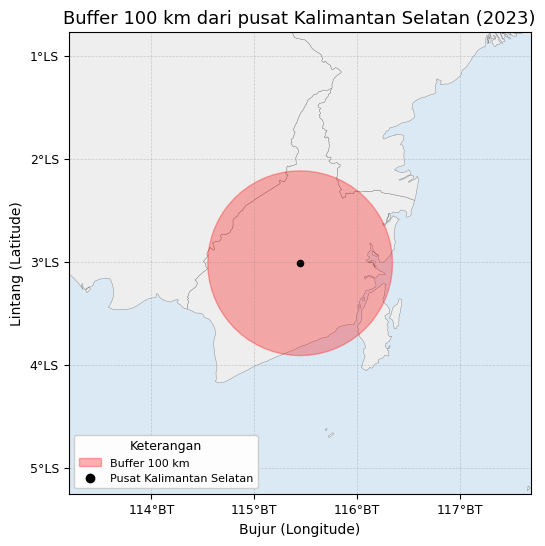

In [12]:
# Catatan: buffer membuat area berbentuk lingkaran dengan radius tertentu dari sebuah titik.
# Radius 100.000 m = 100 km karena koordinat berada dalam meter (EPSG:3857).
top = peta.sort_values(str(TAHUN), ascending=False).iloc[0]
pusat_top = gpd.GeoDataFrame({'Propinsi': [top['Propinsi']]},
                             geometry=[top.geometry.centroid], crs=peta.crs)
buffer_top = pusat_top.copy()
buffer_top['geometry'] = pusat_top.buffer(100_000)

print("Tipe geometri pusat:", pusat_top.geom_type.iloc[0])
print("Tipe geometri hasil buffer:", buffer_top.geom_type.iloc[0])
print(f"Luas area buffer: {buffer_top.area.iloc[0] / 1e6:,.0f} km² (perkiraan, proyeksi Web Mercator)")

fig, ax = plt.subplots(figsize=(10, 6))
peta.plot(ax=ax, color='#eeeeee', edgecolor='grey', linewidth=0.3)
buffer_top.plot(ax=ax, color='red', alpha=0.3, edgecolor='red')
pusat_top.plot(ax=ax, color='black', markersize=20)
minx, miny, maxx, maxy = buffer_top.total_bounds
ax.set_xlim(minx - 150_000, maxx + 150_000)
ax.set_ylim(miny - 150_000, maxy + 150_000)
ax.set_title(f"Buffer 100 km dari pusat {top['Propinsi']} ({TAHUN})", fontsize=13)
tambah_koordinat(ax, langkah=1)
legenda_buffer = [
    Patch(facecolor='red', alpha=0.3, edgecolor='red', label='Buffer 100 km'),
    Line2D([], [], marker='o', linestyle='', color='black', markersize=6, label=f"Pusat {top['Propinsi']}"),
]
tambah_legenda(ax, legenda_buffer, 'Keterangan', loc='lower left')
plt.show()


### Dissolve: menggabungkan provinsi per kelompok pulau
Dissolve menggabungkan polygon provinsi yang berada dalam kelompok pulau yang sama menjadi satu polygon, dengan nilai luas karhutla dan luas wilayah dijumlahkan. Sebelum proses ini, geometri diperbaiki dengan `make_valid()`, karena beberapa polygon pada GeoJSON tidak valid (misalnya bagian garis pantai yang saling berpotongan). Tanpa perbaikan, proses penggabungan akan gagal.

Jumlah geometri tidak valid sebelum diperbaiki: 5
Jumlah polygon setelah dissolve: 7 (sebelumnya 34 provinsi)


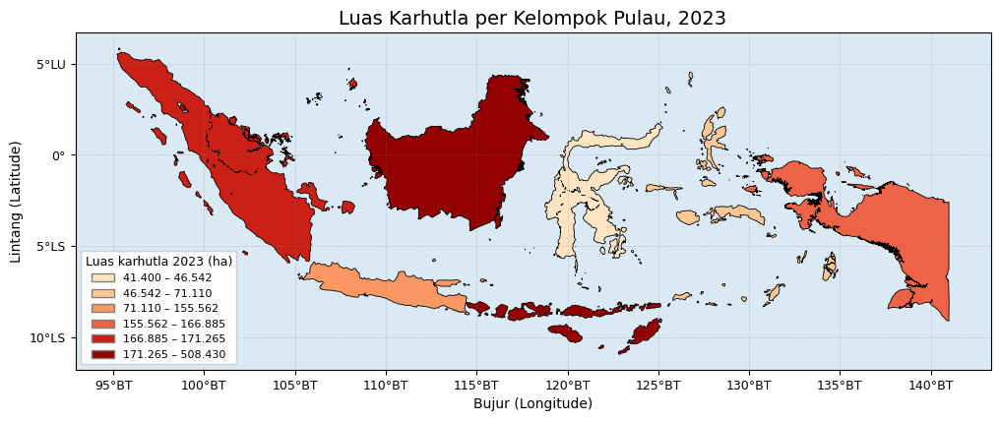

,Pulau,2023,Intensitas_pulau
0,Kalimantan,"508,430.22",0.94
1,Bali & Nusa Tenggara,"171,264.59",2.34
2,Sumatera,"166,885.16",0.35
3,Papua,"155,561.64",0.38
4,Jawa,"71,109.63",0.53
5,Maluku,"46,541.57",0.61
6,Sulawesi,"41,400.09",0.22


In [13]:
# Catatan: make_valid() memperbaiki geometri yang tidak valid. Hasilnya disimpan di peta_valid,
# dan data asli (peta) tidak diubah.
peta_valid = peta.copy()
peta_valid['geometry'] = peta_valid.geometry.make_valid()
print("Jumlah geometri tidak valid sebelum diperbaiki:", int((~peta.geometry.is_valid).sum()))

# dissolve(by='Pulau') menggabungkan polygon yang memiliki nilai 'Pulau' sama.
# aggfunc menentukan cara menghitung kolom numerik; di sini dijumlahkan.
peta_pulau = peta_valid.dissolve(by='Pulau',
                                 aggfunc={str(TAHUN): 'sum', 'Luas_km2': 'sum'}).reset_index()
peta_pulau['Intensitas_pulau'] = peta_pulau[str(TAHUN)] / peta_pulau['Luas_km2']

# Pemeriksaan: total nasional harus sama sebelum dan sesudah dissolve
assert np.isclose(peta_pulau[str(TAHUN)].sum(), peta[str(TAHUN)].sum())
print("Jumlah polygon setelah dissolve:", len(peta_pulau), "(sebelumnya", len(peta), "provinsi)")

cmap_p, norm_p, handles_p = skala_kelas(peta_pulau[str(TAHUN)], 'OrRd', k=6, desimal=0)
fig, ax = plt.subplots(figsize=(12, 6))
peta_pulau.plot(column=str(TAHUN), cmap=cmap_p, norm=norm_p, edgecolor='k', linewidth=0.6, ax=ax)
ax.set_title(f'Luas Karhutla per Kelompok Pulau, {TAHUN}', fontsize=14)
tambah_koordinat(ax)
tambah_legenda(ax, handles_p, f'Luas karhutla {TAHUN} (ha)')
plt.show()

peta_pulau[['Pulau', str(TAHUN), 'Intensitas_pulau']].sort_values(str(TAHUN), ascending=False).reset_index(drop=True)


### Spatial join: memeriksa posisi pusat provinsi
Spatial join *point-in-polygon* memeriksa apakah sebuah titik berada di dalam polygon tertentu. Titik yang diuji adalah pusat (centroid) setiap provinsi. Hasilnya berguna untuk memvalidasi peta titik. Jika pusat provinsi berada di luar wilayahnya, lingkaran pada peta titik dapat tampak berada di laut.

In [14]:
# Catatan: sjoin dengan predicate='within' mencocokkan setiap titik pusat dengan polygon yang memuatnya.
# how='left' tetap mempertahankan semua titik; titik yang tidak berada di dalam polygon mana pun
# akan bernilai NaN pada kolom Propinsi (hasil join).
titik_pusat = gpd.GeoDataFrame(
    {'kode': peta['kode'].values, 'Propinsi_titik': peta['Propinsi'].values},
    geometry=peta.geometry.centroid, crs=peta.crs)

hasil = gpd.sjoin(titik_pusat, peta_valid[['Propinsi', 'geometry']], how='left', predicate='within')

cocok = int((hasil['Propinsi'] == hasil['Propinsi_titik']).sum())
di_luar = hasil[hasil['Propinsi'].isna()]
print(f"Titik pusat yang berada di dalam polygon provinsinya sendiri: {cocok} dari {len(hasil)} provinsi.")
print(f"Titik pusat yang berada di luar polygon mana pun: {len(di_luar)} provinsi.")

di_luar[['Propinsi_titik']].rename(
    columns={'Propinsi_titik': 'Provinsi (pusat berada di luar polygon)'}).reset_index(drop=True)

Titik pusat yang berada di dalam polygon provinsinya sendiri: 27 dari 34 provinsi.
Titik pusat yang berada di luar polygon mana pun: 7 provinsi.


,Provinsi (pusat berada di luar polygon)
0,Maluku Utara
1,Maluku
2,Nusa Tenggara Timur
3,Kepulauan Riau
4,Sulawesi Tengah
5,Sulawesi Utara
6,Bangka Belitung


Sebagian provinsi, umumnya provinsi kepulauan dan provinsi yang berbentuk memanjang, memiliki pusat di luar daratannya. Ini tidak berarti data karhutla keliru, tetapi perlu diperhatikan saat membaca peta titik. Alternatif yang menjamin titik berada di dalam polygon adalah `representative_point()`, yang tidak diterapkan di sini agar peta titik tetap konsisten dengan bagian 11.

---

## 7. Peta Choropleth Luas Karhutla

**Apa yang ditunjukkan:** Luas lahan yang terbakar di setiap provinsi pada tahun yang dipilih (`TAHUN`), digambarkan dengan gradasi warna. Semakin pekat warna sebuah provinsi, semakin luas lahan yang terbakar di wilayah tersebut. Provinsi yang hampir putih hanya mengalami sedikit karhutla atau tidak sama sekali.

**Tujuan peta:** Memperlihatkan provinsi mana yang paling parah terdampak dan apakah karhutla terkonsentrasi di wilayah tertentu. Informasi ini dapat menjadi dasar untuk menentukan wilayah prioritas pencegahan dan penanganan.

**Cara membaca:** Bandingkan kepekatan warna antarprovinsi dengan batang warna (*colorbar*) di sisi kanan peta. Skala warna menggunakan `PowerNorm` (skala berpangkat, tidak linear) karena distribusi data sangat timpang. Tanpa skala ini, provinsi dengan nilai kecil akan tampak sama putihnya dengan provinsi yang bernilai nol. Ubah nilai `TAHUN` di awal notebook untuk melihat tahun lainnya.

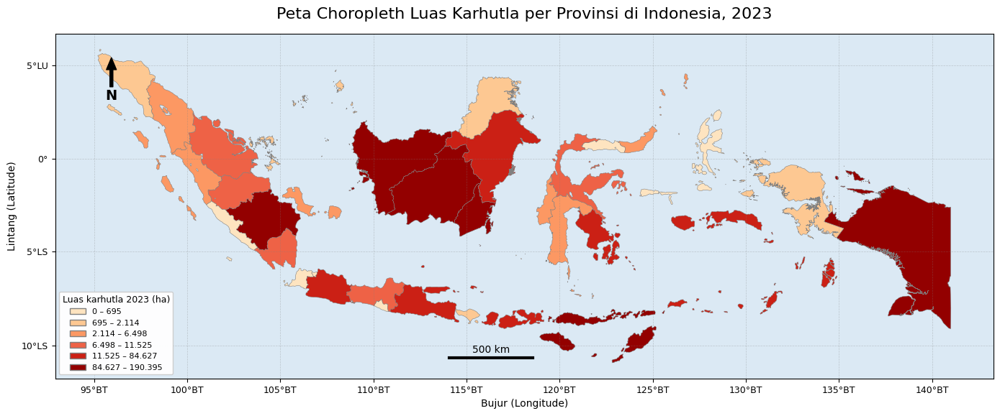

In [15]:
# Catatan: bagian kode ini digunakan untuk menggambar peta choropleth luas karhutla pada TAHUN terpilih.
# Kelas warna dibuat dari data (rentang nilai di legenda sama dengan data pada TAHUN terpilih).
col = str(TAHUN)
cmap_k, norm_k, handles_k = skala_kelas(peta[col], 'OrRd', k=6, desimal=0)

fig, ax = plt.subplots(figsize=(14, 7))
peta.plot(column=col, ax=ax, cmap=cmap_k, norm=norm_k, edgecolor='grey', linewidth=0.4)
ax.set_title(f'Peta Choropleth Luas Karhutla per Provinsi di Indonesia, {TAHUN}', fontsize=16, pad=15)
tambah_koordinat(ax)
tambah_legenda(ax, handles_k, f'Luas karhutla {TAHUN} (ha)')
tambah_elemen_peta(ax)
plt.tight_layout()
plt.savefig(f'peta_choropleth_luas_karhutla_{TAHUN}.png', dpi=300, bbox_inches='tight')  # simpan peta sebagai PNG
plt.show()


In [16]:
# Catatan: bagian kode ini digunakan untuk menghitung ringkasan peta choropleth (total nasional, tiga provinsi terbesar,
# sebaran per kelompok pulau) dan menuliskannya sebagai teks temuan.
d = peta[['Propinsi', 'Pulau', col]].sort_values(col, ascending=False).reset_index(drop=True)
total = d[col].sum()
n_aktif = int((d[col] > 0).sum())
pulau = d.groupby('Pulau')[col].sum().sort_values(ascending=False)
t3 = d.head(3)
baris = [
    f"### Temuan peta choropleth ({TAHUN})",
    f"Pada {TAHUN}, lahan yang terbakar di seluruh Indonesia mencapai **{rp(total)} ha** dan terjadi di {n_aktif} dari {len(d)} provinsi.",
    "Warna paling pekat ada di " + ', '.join(f"**{r['Propinsi']}** ({rp(r[col])} ha)" for _, r in t3.iterrows())
        + f". Ketiganya bersama-sama menyumbang {t3[col].sum() / total * 100:.0f}% dari total nasional, artinya karhutla terpusat di beberapa provinsi dan tidak tersebar merata.",
    f"Menurut kelompok pulau, karhutla terluas berada di **{pulau.index[0]}** ({pulau.iloc[0] / total * 100:.0f}% dari total), "
    f"disusul **{pulau.index[1]}** ({pulau.iloc[1] / total * 100:.0f}%) dan **{pulau.index[2]}** ({pulau.iloc[2] / total * 100:.0f}%). "
    "Angka Papua dan Papua Barat sudah mencakup provinsi pemekarannya.",
]
display(Markdown('\n\n'.join(baris)))

### Temuan peta choropleth (2023)

Pada 2023, lahan yang terbakar di seluruh Indonesia mencapai **1.161.193 ha** dan terjadi di 33 dari 34 provinsi.

Warna paling pekat ada di **Kalimantan Selatan** (190.395 ha), **Kalimantan Tengah** (165.896 ha), **Papua** (154.798 ha). Ketiganya bersama-sama menyumbang 44% dari total nasional, artinya karhutla terpusat di beberapa provinsi dan tidak tersebar merata.

Menurut kelompok pulau, karhutla terluas berada di **Kalimantan** (44% dari total), disusul **Bali & Nusa Tenggara** (15%) dan **Sumatera** (14%). Angka Papua dan Papua Barat sudah mencakup provinsi pemekarannya.

---
## 8. Peta Intensitas Karhutla (Normalisasi ha/km²)

**Apa yang ditunjukkan:** seberapa besar bagian wilayah sebuah provinsi yang terbakar, yaitu luas karhutla dibagi luas provinsi (hektar per km²). Nilai 1 ha/km² berarti 1% dari wilayah provinsi terbakar. Makin pekat warna, makin besar proporsi wilayahnya yang terdampak.

**Tujuan peta:** membandingkan tingkat keparahan karhutla secara adil antar provinsi yang ukurannya berbeda jauh. Provinsi kecil yang sebagian besar wilayahnya terbakar tidak lagi tertutup oleh provinsi besar yang luas absolutnya lebih besar. Ini sama dengan perbedaan antara jumlah penduduk dan kepadatan penduduk pada contoh choropleth dosen.

**Cara membaca:** bandingkan dengan peta luas (bagian 7). Provinsi yang pekat di kedua peta mengalami karhutla yang luas sekaligus berat bagi wilayahnya; provinsi yang pekat hanya di peta intensitas adalah provinsi kecil yang terdampak relatif parah.

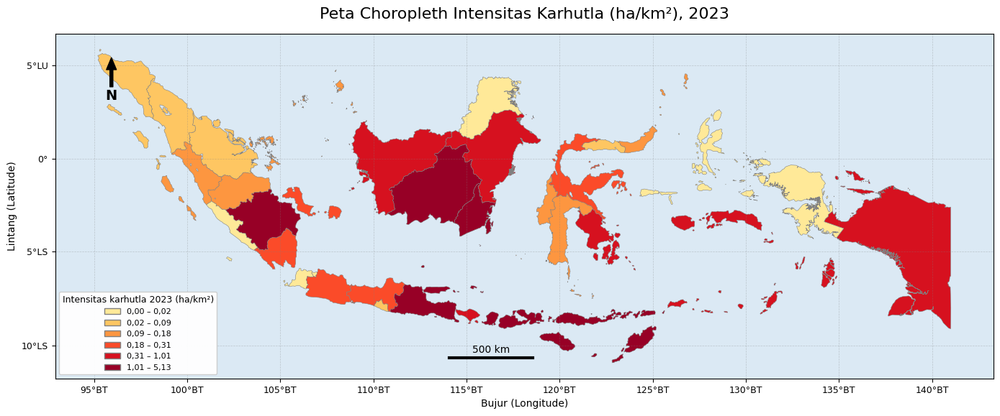

,Propinsi,2023,Intensitas_2023
0,Kalimantan Selatan,"190,394.58",5.13
1,Kalimantan Tengah,"165,896.44",1.07
2,Papua,"154,798.37",0.49
3,Sumatera Selatan,"132,082.86",1.52
4,Kalimantan Barat,"111,848.43",0.75
5,Nusa Tenggara Timur,"102,536.89",2.16
6,Nusa Tenggara Barat,"66,716.43",3.33
7,Jawa Timur,"49,498.32",1.01
8,Maluku,"45,999.39",1.01
9,Kalimantan Timur,"39,494.41",0.31


In [17]:
# Catatan: bagian kode ini digunakan untuk menggambar peta intensitas karhutla (ha/km2), yaitu hasil normalisasi
# luas karhutla terhadap luas provinsi, dan menampilkan 10 provinsi dengan luas karhutla terbesar.
icol = f'Intensitas_{TAHUN}'
cmap_i, norm_i, handles_i = skala_kelas(peta[icol], 'YlOrRd', k=6, desimal=2)

fig, ax = plt.subplots(figsize=(14, 7))
peta.plot(column=icol, ax=ax, cmap=cmap_i, norm=norm_i, edgecolor='grey', linewidth=0.4)
ax.set_title(f'Peta Choropleth Intensitas Karhutla (ha/km²), {TAHUN}', fontsize=16, pad=15)
tambah_koordinat(ax)
tambah_legenda(ax, handles_i, f'Intensitas karhutla {TAHUN} (ha/km²)')
tambah_elemen_peta(ax)
plt.tight_layout()
plt.savefig(f'peta_choropleth_intensitas_{TAHUN}.png', dpi=300, bbox_inches='tight')  # simpan peta sebagai PNG
plt.show()

# 10 provinsi dengan luas karhutla terbesar pada tahun terpilih
peta[['Propinsi', col, icol]].sort_values(col, ascending=False).head(10).reset_index(drop=True)


In [18]:
# Catatan: bagian kode ini digunakan untuk membandingkan peringkat provinsi menurut luas absolut dan menurut intensitas,
# lalu menuliskan perbedaannya sebagai teks temuan.
di = peta[['Propinsi', 'Luas_km2', col, icol]].copy()
top_luas = list(di.sort_values(col, ascending=False).head(5)['Propinsi'])
top_int = di.sort_values(icol, ascending=False).head(5)
naik = [p for p in top_int['Propinsi'] if p not in top_luas]
turun = [p for p in top_luas if p not in list(top_int['Propinsi'])]
r1 = top_int.iloc[0]
baris = [
    f"### Temuan peta intensitas ({TAHUN})",
    f"Provinsi dengan karhutla paling berat bagi wilayahnya adalah **{r1['Propinsi']}**: {rp(r1[icol], 2)} ha terbakar per km², atau sekitar {rp(r1[icol], 1)}% dari luas provinsinya. "
    "Lima teratas: " + '; '.join(f"{r['Propinsi']} ({rp(r[icol], 2)} ha/km²)" for _, r in top_int.iterrows()) + ".",
    ("Dibanding peta luas absolut, " +
     (f"**{', '.join(naik)}** naik ke lima besar karena wilayahnya relatif kecil sementara lahan yang terbakar cukup luas" if naik else "tidak ada provinsi baru yang masuk lima besar") +
     (f", sedangkan **{', '.join(turun)}** turun dari lima besar karena wilayahnya lebih luas sehingga karhutlanya menjadi kecil bila dibanding ukuran provinsi." if turun else ".")),
    "Maknanya: ukuran wilayah mengubah gambaran keparahan. Untuk menilai tekanan karhutla terhadap suatu daerah, peta intensitas lebih tepat; untuk menilai besarnya total lahan yang hilang, peta luas absolut lebih tepat.",
]
display(Markdown('\n\n'.join(baris)))

### Temuan peta intensitas (2023)

Provinsi dengan karhutla paling berat bagi wilayahnya adalah **Kalimantan Selatan**: 5,13 ha terbakar per km², atau sekitar 5,1% dari luas provinsinya. Lima teratas: Kalimantan Selatan (5,13 ha/km²); Nusa Tenggara Barat (3,33 ha/km²); Nusa Tenggara Timur (2,16 ha/km²); Sumatera Selatan (1,52 ha/km²); Kalimantan Tengah (1,07 ha/km²).

Dibanding peta luas absolut, **Nusa Tenggara Barat, Nusa Tenggara Timur** naik ke lima besar karena wilayahnya relatif kecil sementara lahan yang terbakar cukup luas, sedangkan **Papua, Kalimantan Barat** turun dari lima besar karena wilayahnya lebih luas sehingga karhutlanya menjadi kecil bila dibanding ukuran provinsi.

Maknanya: ukuran wilayah mengubah gambaran keparahan. Untuk menilai tekanan karhutla terhadap suatu daerah, peta intensitas lebih tepat; untuk menilai besarnya total lahan yang hilang, peta luas absolut lebih tepat.

---
## 9. Perbandingan Antar Tahun

**Apa yang ditunjukkan:** sembilan peta choropleth, satu untuk tiap tahun 2018–2026, yang memperlihatkan sebaran luas karhutla per provinsi. Semua peta memakai **skala warna yang sama**, jadi warna yang lebih pekat selalu berarti karhutla yang lebih luas, di tahun mana pun.

**Tujuan:** melihat tahun mana yang terburuk, apakah karhutla naik atau turun dari waktu ke waktu, dan apakah provinsi yang terdampak berulang atau berpindah-pindah.

**Cara membaca:** bandingkan kepekatan warna antar peta. Judul tiap peta memuat total nasional tahun tersebut.

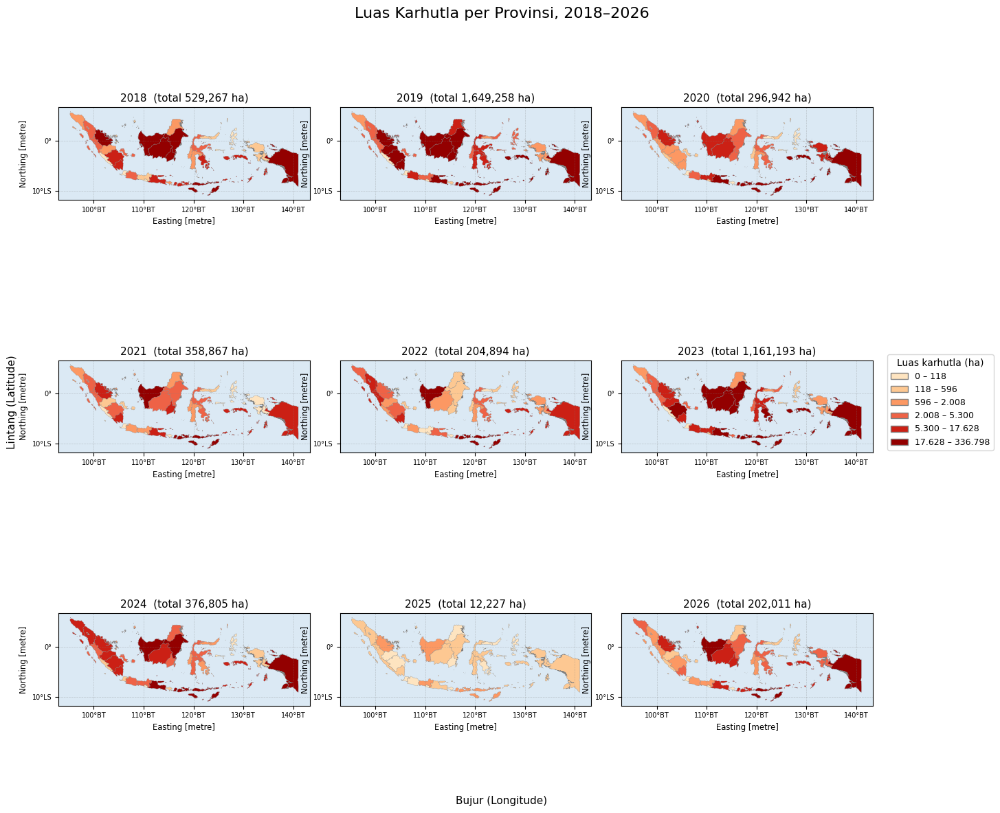

In [19]:
# Catatan: bagian kode ini digunakan untuk membuat sembilan peta (satu per tahun) dengan kelas warna yang sama,
# sehingga warna dapat dibandingkan langsung antar tahun. Legenda dihitung dari seluruh data 2018-2026.
semua_nilai = peta[kolom_tahun].values.ravel()
cmap_a, norm_a, handles_a = skala_kelas(semua_nilai, 'OrRd', k=6, desimal=0)

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, t in zip(axes.ravel(), kolom_tahun):
    peta.plot(column=t, ax=ax, cmap=cmap_a, norm=norm_a, edgecolor='grey', linewidth=0.2)
    ax.set_title(f'{t}  (total {peta[t].sum():,.0f} ha)', fontsize=11)
    tambah_koordinat(ax, langkah=10, label=False, ukuran=7)

fig.supxlabel('Bujur (Longitude)', fontsize=11)
fig.supylabel('Lintang (Latitude)', fontsize=11)
fig.suptitle('Luas Karhutla per Provinsi, 2018–2026', fontsize=16)
fig.legend(handles=handles_a, title='Luas karhutla (ha)', loc='center left',
           bbox_to_anchor=(0.87, 0.5), fontsize=9, title_fontsize=10, frameon=True)
plt.subplots_adjust(left=0.07, right=0.86, bottom=0.07, top=0.92, hspace=0.3, wspace=0.12)
plt.savefig('peta_choropleth_luas_2018_2026.png', dpi=300, bbox_inches='tight')  # simpan peta sebagai PNG
plt.show()


In [20]:
# Catatan: bagian kode ini digunakan untuk meringkas perubahan antar tahun: tahun terburuk dan teringan, lonjakan terbesar,
# serta provinsi yang paling sering menjadi yang terluas. Tabel di akhir memuat provinsi terluas tiap tahun.
total_tahun = peta[kolom_tahun].sum()
puncak, terendah = total_tahun.idxmax(), total_tahun.idxmin()
di_atas_1jt = [t for t in kolom_tahun if total_tahun[t] > 1e6]
prov_puncak = peta.set_index('Propinsi')[kolom_tahun].idxmax()
selisih_th = total_tahun.diff().abs().iloc[1:]
sel_akhir = selisih_th.idxmax(); sel_awal = kolom_tahun[kolom_tahun.index(sel_akhir) - 1]
langganan = prov_puncak.value_counts().head(3)
tabel_tahun = pd.DataFrame({'Total (ha)': total_tahun.round(0),
                            'Provinsi terluas': prov_puncak,
                            'Luas provinsi tsb (ha)': [peta.set_index('Propinsi').loc[prov_puncak[t], t] for t in kolom_tahun]})
baris = [
    "### Temuan perbandingan antar tahun",
    f"Karhutla terburuk terjadi pada **{puncak}** dengan {rp(total_tahun[puncak])} ha, dan paling ringan pada **{terendah}** dengan {rp(total_tahun[terendah])} ha. "
    + (f"Tahun dengan total di atas 1 juta ha: {', '.join(di_atas_1jt)}." if di_atas_1jt else ""),
    f"Perubahannya berupa lonjakan, bukan kenaikan bertahap: perubahan terbesar antar dua tahun berurutan terjadi dari {sel_awal} ke {sel_akhir} "
    f"({rp(total_tahun[sel_awal])} ha menjadi {rp(total_tahun[sel_akhir])} ha). Lonjakan seperti ini lazim dikaitkan dengan musim kemarau panjang, tetapi dataset ini tidak memuat data iklim sehingga hubungan itu tidak diuji di sini.",
    "Provinsi terluas berpindah-pindah antar tahun: " + '; '.join(f"{p} menjadi yang terluas pada {n} dari {len(kolom_tahun)} tahun" for p, n in langganan.items())
    + ". Artinya tidak ada satu provinsi tunggal yang selalu paling parah; titik terparah bergeser mengikuti tahunnya (lihat tabel di bawah).",
    f"Total {kolom_tahun[-1]} sebesar {rp(total_tahun[kolom_tahun[-1]])} ha. Karena merupakan tahun terakhir pada data, bandingkan dengan hati-hati bila periodenya belum satu tahun penuh.",
]
display(Markdown('\n\n'.join(baris)))
tabel_tahun

### Temuan perbandingan antar tahun

Karhutla terburuk terjadi pada **2019** dengan 1.649.258 ha, dan paling ringan pada **2025** dengan 12.227 ha. Tahun dengan total di atas 1 juta ha: 2019, 2023.

Perubahannya berupa lonjakan, bukan kenaikan bertahap: perubahan terbesar antar dua tahun berurutan terjadi dari 2019 ke 2020 (1.649.258 ha menjadi 296.942 ha). Lonjakan seperti ini lazim dikaitkan dengan musim kemarau panjang, tetapi dataset ini tidak memuat data iklim sehingga hubungan itu tidak diuji di sini.

Provinsi terluas berpindah-pindah antar tahun: Nusa Tenggara Timur menjadi yang terluas pada 4 dari 9 tahun; Kalimantan Selatan menjadi yang terluas pada 2 dari 9 tahun; Sumatera Selatan menjadi yang terluas pada 1 dari 9 tahun. Artinya tidak ada satu provinsi tunggal yang selalu paling parah; titik terparah bergeser mengikuti tahunnya (lihat tabel di bawah).

Total 2026 sebesar 202.011 ha. Karena merupakan tahun terakhir pada data, bandingkan dengan hati-hati bila periodenya belum satu tahun penuh.

,Total (ha),Provinsi terluas,Luas provinsi tsb (ha)
2018,"529,267.00",Kalimantan Selatan,"98,637.99"
2019,"1,649,258.00",Sumatera Selatan,"336,798.00"
2020,"296,942.00",Nusa Tenggara Timur,"114,719.00"
2021,"358,867.00",Nusa Tenggara Timur,"137,343.00"
2022,"204,894.00",Nusa Tenggara Timur,"70,637.00"
2023,"1,161,193.00",Kalimantan Selatan,"190,394.58"
2024,"376,805.00",Nusa Tenggara Timur,"113,089.51"
2025,"12,227.00",Nusa Tenggara Barat,"1,867.35"
2026,"202,011.00",Kalimantan Barat,"38,310.86"


---
## 10. Peta Choropleth Interaktif Luas Karhutla per Provinsi Indonesia

**Apa yang ditunjukkan:** data yang sama dengan peta choropleth pada bagian 7, tetapi dapat dijelajahi. Warna wilayah menunjukkan luas karhutla tiap provinsi, dan slider di bawah peta memperlihatkan bagaimana sebaran karhutla berubah dari 2018 hingga 2026.

**Tujuan peta:** membaca angka tiap provinsi langsung dari peta, yaitu luas karhutla, intensitas, dan luas wilayah yang muncul saat kursor diarahkan, serta membandingkan antar tahun tanpa harus membuka tabel.

**Cara membaca:** arahkan kursor ke provinsi untuk melihat angkanya, geser slider atau tekan Play untuk berpindah tahun, gunakan scroll untuk memperbesar, dan seret peta untuk menggesernya. Skala warnanya sama dengan peta statis (berpangkat).

In [21]:
# Catatan: bagian kode ini digunakan untuk menyiapkan data peta interaktif: mengubah data ke format panjang
# (satu baris = satu provinsi pada satu tahun), membuat GeoJSON batas provinsi, dan menentukan skala warna.
# Data ini juga dipakai oleh peta titik interaktif pada bagian 12.
import json
import plotly.express as px
import plotly.io as pio

# Renderer: Colab memakai 'colab', Jupyter / VS Code memakai 'notebook_connected'
try:
    import google.colab
    pio.renderers.default = 'colab'
except ImportError:
    pio.renderers.default = 'notebook_connected'

# Data format panjang: satu baris = satu provinsi pada satu tahun
base = peta.to_crs("EPSG:4326")[['kode', 'Propinsi', 'Luas_km2', 'geometry']].copy()
base['kode'] = base['kode'].astype(str)

long_df = pd.concat([
    base[['kode', 'Propinsi', 'Luas_km2']].assign(
        Tahun=str(t),
        Luas_ha=peta[t].values,
        Intensitas=peta[f'Intensitas_{t}'].values)
    for t in kolom_tahun], ignore_index=True)

# Skala warna berpangkat (sama seperti peta statis) supaya provinsi bernilai kecil tetap terlihat
VMAX = long_df['Luas_ha'].max()
GAMMA = 0.4
long_df['Skala'] = (long_df['Luas_ha'] / VMAX) ** GAMMA

# GeoJSON batas provinsi, id fitur = kode provinsi
geojson = json.loads(base.set_index('kode')[['Propinsi', 'geometry']].to_json())

tick_nilai = [0, 1000, 10000, 50000, 100000, 200000, 300000]
tick_nilai = [v for v in tick_nilai if v <= VMAX]
tick_pos = [(v / VMAX) ** GAMMA for v in tick_nilai]

print("Siap:", long_df.shape[0], "baris data (", len(base), "provinsi x", len(kolom_tahun), "tahun )")

Siap: 306 baris data ( 34 provinsi x 9 tahun )


In [22]:
# Catatan: bagian kode ini digunakan untuk membuat peta choropleth interaktif dengan hover dan slider tahun.
# Peta CHOROPLETH interaktif (hover + slider tahun)
etiket = {'Luas_ha': 'Luas karhutla (ha)', 'Intensitas': 'Intensitas (ha/km²)', 'Luas_km2': 'Luas wilayah (km²)'}
hover = {'Luas_ha': ':,.2f', 'Intensitas': ':.3f', 'Luas_km2': ':,.0f', 'Skala': False, 'kode': False, 'Tahun': False}

# PERUBAHAN 1: skala warna lebih kontras (dari 'OrRd' ke 'YlOrRd')
skala_warna = 'YlOrRd'

if hasattr(px, 'choropleth_map'):                      # plotly >= 5.24
    fig = px.choropleth_map(long_df, geojson=geojson, locations='kode', color='Skala',
                            color_continuous_scale=skala_warna, range_color=(0, 1),
                            animation_frame='Tahun', hover_name='Propinsi',
                            hover_data=hover, labels=etiket,
                            map_style='open-street-map', center={'lat': -2.5, 'lon': 118},
                            zoom=3.3, opacity=0.8, height=620)
else:                                                   # plotly versi lama
    fig = px.choropleth_mapbox(long_df, geojson=geojson, locations='kode', color='Skala',
                               color_continuous_scale=skala_warna, range_color=(0, 1),
                               animation_frame='Tahun', hover_name='Propinsi',
                               hover_data=hover, labels=etiket,
                               mapbox_style='open-street-map', center={'lat': -2.5, 'lon': 118},
                               zoom=3.3, opacity=0.8, height=620)

# PERUBAHAN 2: garis batas hitam pada tiap daerah (muncul/tebal saat hover)
fig.update_traces(
    marker_line_color='black',      # warna batas daerah = hitam
    marker_line_width=0.5,          # ketebalan default (tipis)
    selector=dict(type='choroplethmap') if hasattr(px, 'choropleth_map')
             else dict(type='choroplethmapbox')
)
# efek hover: pertebal garis hitam ketika kursor mendekati daerah
fig.update_layout(
    hoverlabel=dict(bgcolor='white', font_size=12),
    title='Luas Karhutla per Provinsi di Indonesia',
    margin=dict(l=0, r=0, t=50, b=0),
    coloraxis_colorbar=dict(title='Luas karhutla (ha)', tickvals=tick_pos,
                            ticktext=[f'{v:,.0f}'.replace(',', '.') for v in tick_nilai]))
fig.show()
fig.write_html('peta_interaktif_plotly_choropleth.html')    # cadangan, bisa dibuka di browser

In [23]:
# Catatan: bagian kode ini digunakan untuk menuliskan temuan peta interaktif: membandingkan tahun terburuk dan tahun terendah
# berdasarkan jumlah provinsi dengan karhutla di atas 10.000 ha.
tot_th = peta[kolom_tahun].sum()
th_max, th_min = tot_th.idxmax(), tot_th.idxmin()
def ringkas(t):
    kolom = peta[['Propinsi', t]].sort_values(t, ascending=False)
    return kolom, int((kolom[t] >= 10000).sum())
k_max, n_max = ringkas(th_max)
k_min, n_min = ringkas(th_min)
baris = [
    "### Temuan peta interaktif",
    f"Saat slider berada pada tahun terburuk (**{th_max}**), {n_max} provinsi memiliki karhutla di atas 10.000 ha, dengan yang terluas di "
    + ', '.join(f"{r['Propinsi']} ({rp(r[th_max])} ha)" for _, r in k_max.head(3).iterrows()) + ".",
    f"Pada tahun teringan (**{th_min}**), " + ("tidak ada provinsi" if n_min == 0 else f"hanya {n_min} provinsi")
    + f" yang melewati 10.000 ha dan provinsi terluasnya ({k_min.iloc[0]['Propinsi']}) hanya {rp(k_min.iloc[0][th_min])} ha, sehingga peta tampak hampir seluruhnya pucat.",
    "Dengan mengarahkan kursor, luas absolut dan intensitas dapat dibandingkan langsung pada satu provinsi: provinsi yang luas karhutlanya besar belum tentu intensitasnya tinggi, dan sebaliknya.",
]
display(Markdown('\n\n'.join(baris)))

### Temuan peta interaktif

Saat slider berada pada tahun terburuk (**2019**), 16 provinsi memiliki karhutla di atas 10.000 ha, dengan yang terluas di Sumatera Selatan (336.798 ha), Kalimantan Tengah (317.749 ha), Kalimantan Barat (151.919 ha).

Pada tahun teringan (**2025**), tidak ada provinsi yang melewati 10.000 ha dan provinsi terluasnya (Nusa Tenggara Barat) hanya 1.867 ha, sehingga peta tampak hampir seluruhnya pucat.

Dengan mengarahkan kursor, luas absolut dan intensitas dapat dibandingkan langsung pada satu provinsi: provinsi yang luas karhutlanya besar belum tentu intensitasnya tinggi, dan sebaliknya.

---
## 11. Peta Titik Karhutla (Proportional Symbol)

**Apa yang ditunjukkan:** besarnya karhutla tiap provinsi dalam bentuk lingkaran yang diletakkan di pusat provinsi (`centroid`). Makin besar dan makin gelap lingkaran, makin luas lahan yang terbakar. Polygon provinsi dibuat abu-abu muda sebagai latar.

**Tujuan peta:** membuat besaran karhutla antar provinsi bisa dibandingkan sekilas tanpa dipengaruhi luas wilayah provinsi (provinsi besar tidak otomatis tampak lebih parah hanya karena areanya luas), sekaligus menunjukkan letak geografis provinsi-provinsi dengan karhutla terbesar.

**Cara membaca:** lihat ukuran lingkaran dengan legenda "Ukuran titik" di kiri bawah, dan warnanya dengan batang warna di kanan. Titik menandai pusat provinsi, bukan lokasi api yang sesungguhnya.

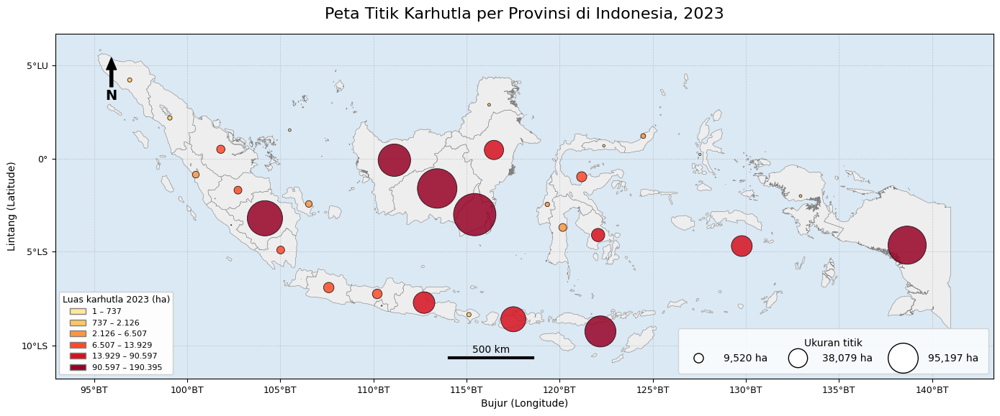

In [24]:
# Catatan: bagian kode ini digunakan untuk menggambar peta titik (proportional symbol): centroid setiap provinsi dijadikan titik
# dengan ukuran dan warna yang mengikuti luas karhutla. Provinsi tanpa karhutla tidak digambar.
titik = peta.copy()
titik['geometry'] = titik.geometry.centroid
titik = titik[titik[col] > 0]          # provinsi tanpa karhutla tidak digambar

ukuran_maks = 1800
ukuran = ukuran_maks * (titik[col] / peta[col].max())   # luas lingkaran proporsional dengan nilai
cmap_t, norm_t, handles_t = skala_kelas(titik[col], 'YlOrRd', k=6, desimal=0)

fig, ax = plt.subplots(figsize=(14, 7))
peta.plot(ax=ax, color='#eeeeee', edgecolor='grey', linewidth=0.4)
ax.scatter(titik.geometry.x, titik.geometry.y, s=ukuran, c=titik[col],
           cmap=cmap_t, norm=norm_t, edgecolor='black', linewidth=0.6, alpha=0.85, zorder=3)

# Legenda warna (kelas dari data) dan legenda ukuran (lingkaran)
leg_warna = tambah_legenda(ax, handles_t, f'Luas karhutla {TAHUN} (ha)', loc='lower left')
ax.add_artist(leg_warna)
nilai_legenda = [peta[col].max() * f for f in (0.05, 0.2, 0.5)]
handles_ukuran = [Line2D([], [], marker='o', linestyle='', color='white', markeredgecolor='black',
                         markersize=np.sqrt(ukuran_maks * v / peta[col].max()),
                         label=f'{v:,.0f} ha') for v in nilai_legenda]
ax.legend(handles=handles_ukuran, title='Ukuran titik', loc='lower right', ncol=3,
          columnspacing=2.0, handletextpad=1.5, borderpad=1.0, frameon=True, facecolor='white')

ax.set_title(f'Peta Titik Karhutla per Provinsi di Indonesia, {TAHUN}', fontsize=16, pad=15)
tambah_koordinat(ax)
tambah_elemen_peta(ax)
plt.tight_layout()
plt.savefig(f'peta_titik_karhutla_{TAHUN}.png', dpi=300, bbox_inches='tight')  # simpan peta sebagai PNG
plt.show()


In [25]:
# Catatan: bagian kode ini digunakan untuk menyusun teks temuan peta titik: provinsi dengan lingkaran terbesar,
# koordinat pusatnya, dan jumlah provinsi yang nilainya sangat kecil.
tp = peta[peta[col] > 0]
besar = tp[tp[col] >= 0.5 * peta[col].max()].sort_values(col, ascending=False)
kecil = int((peta[col] < 0.02 * peta[col].max()).sum())
baris = [
    f"### Temuan peta titik ({TAHUN})",
    f"Lingkaran terbesar dan tergelap berada di {', '.join(besar['Propinsi'])}, yaitu provinsi yang luas karhutlanya minimal setengah dari nilai tertinggi ({rp(peta[col].max())} ha). "
    f"Pusat provinsi-provinsi tersebut terletak pada lintang {rp(besar['Lintang'].min(), 1)}° s.d. {rp(besar['Lintang'].max(), 1)}° dan bujur {rp(besar['Bujur'].min(), 1)}° s.d. {rp(besar['Bujur'].max(), 1)}°.",
    f"Sebaliknya, {kecil} provinsi memiliki luas karhutla kurang dari 2% nilai tertinggi sehingga lingkarannya nyaris tidak terlihat, menandakan karhutla yang sangat kecil dibanding provinsi teratas.",
    "Perbedaan dengan peta choropleth: pada peta titik, provinsi kecil yang mengalami karhutla besar tetap terlihat jelas karena yang dibandingkan adalah ukuran lingkaran, bukan luas warna wilayah.",
]
display(Markdown('\n\n'.join(baris)))
tp[['Propinsi', 'Lintang', 'Bujur', col]].sort_values(col, ascending=False).head(10).reset_index(drop=True)

### Temuan peta titik (2023)

Lingkaran terbesar dan tergelap berada di Kalimantan Selatan, Kalimantan Tengah, Papua, Sumatera Selatan, Kalimantan Barat, Nusa Tenggara Timur, yaitu provinsi yang luas karhutlanya minimal setengah dari nilai tertinggi (190.395 ha). Pusat provinsi-provinsi tersebut terletak pada lintang -9,3° s.d. -0,1° dan bujur 104,2° s.d. 138,7°.

Sebaliknya, 14 provinsi memiliki luas karhutla kurang dari 2% nilai tertinggi sehingga lingkarannya nyaris tidak terlihat, menandakan karhutla yang sangat kecil dibanding provinsi teratas.

Perbedaan dengan peta choropleth: pada peta titik, provinsi kecil yang mengalami karhutla besar tetap terlihat jelas karena yang dibandingkan adalah ukuran lingkaran, bukan luas warna wilayah.

,Propinsi,Lintang,Bujur,2023
0,Kalimantan Selatan,-3.01,115.44,"190,394.58"
1,Kalimantan Tengah,-1.60,113.42,"165,896.44"
2,Papua,-4.65,138.67,"154,798.37"
3,Sumatera Selatan,-3.21,104.17,"132,082.86"
4,Kalimantan Barat,-0.08,111.13,"111,848.43"
5,Nusa Tenggara Timur,-9.26,122.19,"102,536.89"
6,Nusa Tenggara Barat,-8.61,117.52,"66,716.43"
7,Jawa Timur,-7.73,112.72,"49,498.32"
8,Maluku,-4.70,129.78,"45,999.39"
9,Kalimantan Timur,0.47,116.47,"39,494.41"


---
## 12. Peta Titik Interaktif Karhutla per Provinsi

**Apa yang ditunjukkan:** peta titik pada bagian 11 dalam bentuk interaktif. Ukuran dan warna lingkaran menunjukkan luas karhutla tiap provinsi, dan slider tahun memperlihatkan bagaimana lingkaran membesar atau mengecil dari tahun ke tahun.

**Tujuan peta:** membandingkan besaran karhutla antar provinsi dan antar tahun secara langsung, sambil membaca angka pastinya melalui hover tanpa membuka tabel.

**Cara membaca:** arahkan kursor ke lingkaran untuk melihat luas karhutla, intensitas, dan luas wilayah provinsi. Geser slider atau tekan Play untuk berpindah tahun. Seperti pada peta statis, lingkaran berada di pusat provinsi dan bukan di lokasi api yang sebenarnya.

In [26]:
# Catatan: bagian kode ini digunakan untuk membuat peta titik interaktif (proportional symbol) dengan hover dan slider tahun.
# Peta TITIK interaktif (proportional symbol): ukuran & warna titik = luas karhutla
pusat = peta.geometry.centroid.to_crs("EPSG:4326")   # centroid dihitung di CRS metrik, lalu ke lat/lon
titik_df = long_df.merge(
    pd.DataFrame({'kode': peta['kode'].astype(str).values, 'lon': pusat.x.values, 'lat': pusat.y.values}),
    on='kode')

if hasattr(px, 'scatter_map'):
    fig2 = px.scatter_map(titik_df, lat='lat', lon='lon', size='Luas_ha', color='Skala',
                          color_continuous_scale='YlOrRd', range_color=(0, 1), size_max=45,
                          animation_frame='Tahun', hover_name='Propinsi',
                          hover_data={**hover, 'lat': False, 'lon': False}, labels=etiket,
                          map_style='open-street-map', center={'lat': -2.5, 'lon': 118},
                          zoom=3.3, height=620)
else:
    fig2 = px.scatter_mapbox(titik_df, lat='lat', lon='lon', size='Luas_ha', color='Skala',
                             color_continuous_scale='YlOrRd', range_color=(0, 1), size_max=45,
                             animation_frame='Tahun', hover_name='Propinsi',
                             hover_data={**hover, 'lat': False, 'lon': False}, labels=etiket,
                             mapbox_style='open-street-map', center={'lat': -2.5, 'lon': 118},
                             zoom=3.3, height=620)

fig2.update_layout(
    title='Titik Karhutla per Provinsi (ukuran & warna = luas karhutla)',
    margin=dict(l=0, r=0, t=50, b=0),
    coloraxis_colorbar=dict(title='Luas karhutla (ha)', tickvals=tick_pos,
                            ticktext=[f'{v:,.0f}'.replace(',', '.') for v in tick_nilai]))
fig2.show()
fig2.write_html('peta_interaktif_plotly_titik.html')

In [27]:
# Catatan: bagian kode ini digunakan untuk menuliskan temuan peta titik interaktif: ukuran lingkaran terbesar pada tahun
# terburuk dibanding tahun terendah, serta provinsi yang memiliki lingkaran terbesar pada tiap tahun.
tot_pt = peta[kolom_tahun].sum()
t_max, t_min = tot_pt.idxmax(), tot_pt.idxmin()
prov_th = peta.set_index('Propinsi')[kolom_tahun]
terbesar = prov_th.idxmax()          # provinsi dengan lingkaran terbesar pada setiap tahun
nilai_t = prov_th.max()              # luas karhutla provinsi tersebut
baris = [
    "### Temuan peta titik interaktif",
    f"Pada tahun terburuk (**{t_max}**), lingkaran terbesar berada di **{terbesar[t_max]}** dengan {rp(nilai_t[t_max])} ha. "
    f"Pada tahun teringan (**{t_min}**), lingkaran terbesar hanya berada di {terbesar[t_min]} dengan {rp(nilai_t[t_min])} ha"
    + (f", atau sekitar {rp(nilai_t[t_max] / nilai_t[t_min])} kali lebih kecil." if nilai_t[t_min] > 0 else ".")
    + " Karena ukuran dan warna lingkaran memakai skala yang sama untuk semua tahun, lingkaran pada tahun teringan tampak jauh lebih kecil dan lebih pucat.",
    f"Selama {len(kolom_tahun)} tahun, lingkaran terbesar berpindah di antara {terbesar.nunique()} provinsi: {', '.join(terbesar.unique())}. "
    "Perpindahan ini menunjukkan bahwa pusat karhutla tidak selalu berada di provinsi yang sama dari tahun ke tahun.",
    "Hover pada lingkaran menampilkan luas absolut, intensitas, dan luas wilayah sekaligus, sehingga besarnya lingkaran dapat dikaitkan dengan ukuran provinsinya.",
]
display(Markdown('\n\n'.join(baris)))

### Temuan peta titik interaktif

Pada tahun terburuk (**2019**), lingkaran terbesar berada di **Sumatera Selatan** dengan 336.798 ha. Pada tahun teringan (**2025**), lingkaran terbesar hanya berada di Nusa Tenggara Barat dengan 1.867 ha, atau sekitar 180 kali lebih kecil. Karena ukuran dan warna lingkaran memakai skala yang sama untuk semua tahun, lingkaran pada tahun teringan tampak jauh lebih kecil dan lebih pucat.

Selama 9 tahun, lingkaran terbesar berpindah di antara 5 provinsi: Kalimantan Selatan, Sumatera Selatan, Nusa Tenggara Timur, Nusa Tenggara Barat, Kalimantan Barat. Perpindahan ini menunjukkan bahwa pusat karhutla tidak selalu berada di provinsi yang sama dari tahun ke tahun.

Hover pada lingkaran menampilkan luas absolut, intensitas, dan luas wilayah sekaligus, sehingga besarnya lingkaran dapat dikaitkan dengan ukuran provinsinya.

---
## 13. Peta Titik Panas Indonesia FIRMS 2026

**Apa yang ditunjukkan:** lokasi setiap deteksi titik panas (*hotspot*) dari satelit VIIRS (SNPP) pada periode 1 Januari s.d. 2 November 2026, digambar di koordinat aslinya. Berbeda dengan bagian 11, setiap titik di sini adalah lokasi deteksi yang sebenarnya, bukan pusat provinsi.

**Tujuan:** memetakan sebaran api sebenarnya di Indonesia dan menguji apakah hasilnya sejalan dengan data luas per provinsi pada bagian 7.

**Catatan sumber:** data bersumber dari NASA FIRMS. Titik panas bukan luas terbakar. Satu deteksi VIIRS mewakili piksel sekitar 375 m (kira-kira 14 ha) sebagai perkiraan kasar. Data Agustus s.d. November berasal dari NRT (*near real time*) yang masih bersifat sementara.

In [28]:
# Catatan: membaca data titik panas FIRMS. File dicari di folder notebook dan subfoldernya (zip atau CSV).
# Deteksi dengan tingkat kepercayaan n (normal) dan h (tinggi) dipakai.
import os, glob, zipfile

FIRMS_ZIP = 'DL_FIRE_SV-C2_839983.zip'
FIRMS_ARSIP = 'fire_archive_SV-C2_839983.csv'
FIRMS_NRT = 'fire_nrt_SV-C2_839983.csv'
KONFIDENSI_DIPAKAI = ['n', 'h']   # 'l' (rendah) tidak dipakai karena sering berupa noise

cari = lambda nama: sorted(glob.glob(f'**/{nama}', recursive=True))
csv_arsip, csv_nrt = cari(FIRMS_ARSIP), cari(FIRMS_NRT)
zip_firms = cari(FIRMS_ZIP)

if csv_arsip and csv_nrt:
    arsip = pd.read_csv(csv_arsip[0])
    nrt = pd.read_csv(csv_nrt[0])
    print("Dibaca dari:", csv_arsip[0], "dan", csv_nrt[0])
elif zip_firms:
    with zipfile.ZipFile(zip_firms[0]) as z:
        arsip = pd.read_csv(z.open(FIRMS_ARSIP))
        nrt = pd.read_csv(z.open(FIRMS_NRT))
    print("Dibaca dari zip:", zip_firms[0])
else:
    raise FileNotFoundError(
        f"Data FIRMS tidak ditemukan di folder notebook maupun subfoldernya. Letakkan '{FIRMS_ZIP}' "
        f"atau kedua file CSV ('{FIRMS_ARSIP}' dan '{FIRMS_NRT}') di folder ini.")

firms = pd.concat([arsip, nrt], ignore_index=True)
firms['acq_date'] = pd.to_datetime(firms['acq_date'])
firms['confidence'] = firms['confidence'].astype(str)
print("Total deteksi (arsip + NRT):", f"{len(firms):,}".replace(',', '.'))
print("Rentang tanggal:", firms['acq_date'].min().date(), "s.d.", firms['acq_date'].max().date())
print("Sebaran tingkat kepercayaan:", firms['confidence'].value_counts().to_dict())

firms = firms[firms['confidence'].isin(KONFIDENSI_DIPAKAI)].reset_index(drop=True)
print("Deteksi yang dipakai (confidence n/h):", f"{len(firms):,}".replace(',', '.'))
firms.head(3)

Dibaca dari: DL_FIRE_SV-C2_839983\fire_archive_SV-C2_839983.csv dan DL_FIRE_SV-C2_839983\fire_nrt_SV-C2_839983.csv
Total deteksi (arsip + NRT): 626.067
Rentang tanggal: 2026-01-01 s.d. 2026-11-02
Sebaran tingkat kepercayaan: {'n': 573385, 'l': 30607, 'h': 22075}
Deteksi yang dipakai (confidence n/h): 595.460


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,-2.01,121.43,330.28,0.45,0.39,2026-01-01,513,SNPP,SNPP,n,2,270.03,3.66,D,2.00
1,-3.90,122.42,331.70,0.43,0.38,2026-01-01,513,SNPP,SNPP,n,2,292.70,4.89,D,2.00
2,-2.00,121.43,331.17,0.45,0.39,2026-01-01,513,SNPP,SNPP,n,2,274.52,5.97,D,2.00


In [29]:
# Catatan: titik diubah menjadi GeoDataFrame (lat/lon, EPSG:4326), lalu diproyeksikan ke EPSG:3857 agar sama
# dengan peta. Spatial join point-in-polygon dipakai untuk mengetahui provinsi tempat setiap titik panas berada.
titik_api = gpd.GeoDataFrame(
    firms[['acq_date', 'brightness', 'frp', 'confidence']].copy(),
    geometry=gpd.points_from_xy(firms['longitude'], firms['latitude']),
    crs='EPSG:4326').to_crs('EPSG:3857')

# make_valid dijalankan sendiri di sini, sehingga sel ini tidak bergantung pada urutan sel sebelumnya
batas = peta[['Propinsi', 'geometry']].copy()
batas['geometry'] = batas.geometry.make_valid()
titik_api = gpd.sjoin(titik_api, batas, how='left', predicate='within').drop(columns='index_right')

di_luar = int(titik_api['Propinsi'].isna().sum())
print(f"Titik yang berada di dalam provinsi: {len(titik_api) - di_luar:,}".replace(',', '.'))
print(f"Titik di laut atau di luar batas peta: {di_luar:,}".replace(',', '.'))

Titik yang berada di dalam provinsi: 589.974
Titik di laut atau di luar batas peta: 5.522


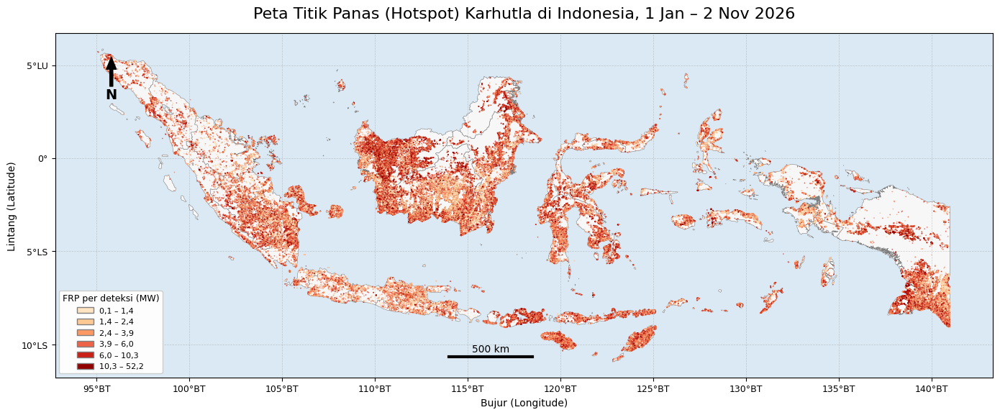

In [30]:
# Catatan: Setiap titik adalah satu deteksi api, diwarnai menurut FRP (daya radiasi api, MW).
# Titik dibuat kecil dan sedikit transparan karena jumlahnya besar. Nilai FRP dipotong di persentil 99
# agar warna tidak didominasi oleh sedikit deteksi yang ekstrem. Kelas legenda dihitung dari nilai FRP tersebut.
frp_batas = np.percentile(titik_api['frp'], 99)
frp_tampil = titik_api['frp'].clip(upper=frp_batas)
cmap_f, norm_f, handles_f = skala_kelas(frp_tampil, 'OrRd', k=6, desimal=1)

fig, ax = plt.subplots(figsize=(14, 7))
peta.plot(ax=ax, color='#f7f7f7', edgecolor='grey', linewidth=0.4)
ax.scatter(titik_api.geometry.x, titik_api.geometry.y,
           c=frp_tampil, cmap=cmap_f, norm=norm_f,
           s=1.5, alpha=0.6, linewidths=0, zorder=3, rasterized=True)

ax.set_title('Peta Titik Panas (Hotspot) Karhutla di Indonesia, 1 Jan – 2 Nov 2026', fontsize=16, pad=15)
tambah_koordinat(ax)
tambah_legenda(ax, handles_f, 'FRP per deteksi (MW)')
tambah_elemen_peta(ax)
plt.tight_layout()
plt.savefig('peta_titik_panas_fires_2026.png', dpi=300, bbox_inches='tight')  # simpan peta sebagai PNG
plt.show()


### Peta titik panas interaktif

**Apa yang ditunjukkan:** setiap titik adalah satu deteksi titik panas FIRMS. Arahkan kursor ke titik untuk melihat tanggal, FRP, kecerahan, tingkat kepercayaan, dan provinsi tempat titik tersebut berada. Slider dan tombol Play memindahkan tampilan dari Januari sampai November 2026.

**Tujuan:** memeriksa detail setiap deteksi tanpa harus membaca tabel, serta melihat bagaimana sebaran api bergeser dari bulan ke bulan.

**Catatan ukuran:** seluruh data berisi sekitar 595 ribu titik. Agar notebook tetap ringan, setiap bulan ditampilkan sebagai contoh acak tetap sebanyak `MAKS_TITIK_PER_BULAN` titik. Jumlah dan angka lengkap tetap dihitung dari seluruh data pada bagian 13 dan 14. Nilai ini bisa dinaikkan jika komputer Anda kuat, dengan konsekuensi file notebook menjadi lebih besar.

In [31]:
# Catatan: peta titik panas interaktif. Setiap titik bisa diarahkan kursornya, dan slider/Play menampilkan
# sebaran per bulan. Warna memakai palet merah yang sama dengan peta statis (dipotong di persentil 99 FRP).
# Untuk menjaga ukuran notebook, tiap bulan diambil contoh acak tetap (random_state=42) sebanyak MAKS_TITIK_PER_BULAN.
import plotly.express as px
# Pastikan titik_api sudah memiliki kolom 'Propinsi' (hasil spatial join ke batas provinsi)
if 'Propinsi' not in titik_api.columns:
    batas = peta[['Propinsi', 'geometry']].copy()
    batas['geometry'] = batas.geometry.make_valid()
    titik_api = (gpd.sjoin(titik_api, batas, how='left', predicate='within')
                   .drop(columns=['index_right'], errors='ignore'))
    print("Spatial join dijalankan ulang untuk titik_api.")
NAMA_BULAN = {1: 'Januari', 2: 'Februari', 3: 'Maret', 4: 'April', 5: 'Mei', 6: 'Juni',
              7: 'Juli', 8: 'Agustus', 9: 'September', 10: 'Oktober', 11: 'November', 12: 'Desember'}
MAKS_TITIK_PER_BULAN = 2000
KEYAKINAN = {'n': 'normal', 'h': 'tinggi'}

# Palet merah kontras, sama dengan peta statis: merah muda terang -> merah -> merah tua pekat
MERAH_KONTRAS = [[0.0, '#ffc9b8'], [0.33, '#ff4d2e'], [0.66, '#d10000'], [1.0, '#5c0000']]

pt = titik_api.dropna(subset=['Propinsi']).copy()
pt_ll = pt.to_crs('EPSG:4326')
pt['lon'] = pt_ll.geometry.x.values
pt['lat'] = pt_ll.geometry.y.values
pt['Bulan'] = pt['acq_date'].dt.month.map(lambda m: f"{m:02d} {NAMA_BULAN[m]} 2026")
pt['Tanggal'] = pt['acq_date'].dt.strftime('%d %b %Y')
pt['Keyakinan'] = pt['confidence'].map(KEYAKINAN)
frp_batas_i = float(np.percentile(pt['frp'], 99))
pt['frp_tampil'] = pt['frp'].clip(upper=frp_batas_i)

# Ambil contoh acak tetap per bulan tanpa groupby-apply
sampel = (pt.sample(frac=1, random_state=42)
            .groupby('Bulan', sort=False)
            .head(MAKS_TITIK_PER_BULAN)
            .sort_values('Bulan')
            .reset_index(drop=True))
print(f"Titik yang ditampilkan: {len(sampel):,} dari {len(pt):,} (contoh per bulan)".replace(',', '.'))

hover_i = {'Tanggal': True, 'frp': ':.2f', 'brightness': ':.1f', 'Keyakinan': True,
           'lat': ':.3f', 'lon': ':.3f', 'Bulan': False, 'frp_tampil': False}
etiket_i = {'frp': 'FRP (MW)', 'brightness': 'Kecerahan (K)'}

if hasattr(px, 'scatter_map'):                          # plotly >= 5.24
    fig_t = px.scatter_map(sampel, lat='lat', lon='lon', color='frp_tampil',
                           color_continuous_scale=MERAH_KONTRAS, range_color=(0, frp_batas_i),
                           animation_frame='Bulan', hover_name='Propinsi', hover_data=hover_i,
                           labels=etiket_i, map_style='open-street-map',
                           center={'lat': -2.5, 'lon': 118}, zoom=3.3, height=640)
else:                                                   # plotly versi lama
    fig_t = px.scatter_mapbox(sampel, lat='lat', lon='lon', color='frp_tampil',
                              color_continuous_scale=MERAH_KONTRAS, range_color=(0, frp_batas_i),
                              animation_frame='Bulan', hover_name='Propinsi', hover_data=hover_i,
                              labels=etiket_i, mapbox_style='open-street-map',
                              center={'lat': -2.5, 'lon': 118}, zoom=3.3, height=640)

fig_t.update_traces(marker=dict(size=6, opacity=0.9))
fig_t.update_layout(
    title='Titik Panas (Hotspot) Karhutla 2026',
    margin=dict(l=0, r=0, t=50, b=0),
    coloraxis_colorbar=dict(title='FRP (MW)'))
fig_t.show()

Titik yang ditampilkan: 22.000 dari 589.974 (contoh per bulan)


---
## 14. Peta Choropleth Jumlah Titik Panas per Provinsi

**Apa yang ditunjukkan:** jumlah deteksi titik panas FIRMS (bagian 13) di setiap provinsi, dengan gradasi warna. Choropleth ini dibangun langsung dari dataset titik (lat/lon), bukan dari tabel luas.

**Tujuan:** memetakan kebakaran dari data titik, dan membandingkannya dengan luas karhutla resmi pada bagian 7.

**Cara kerja:** titik di-*join* ke provinsi dengan spatial join (bagian 13), lalu dihitung jumlahnya per provinsi. Hasilnya juga dibagi luas wilayah menjadi kepadatan per 1.000 km², supaya provinsi besar tidak otomatis tampak paling terdampak.

Total titik panas yang masuk provinsi: 589.974
Provinsi tanpa titik panas: 0


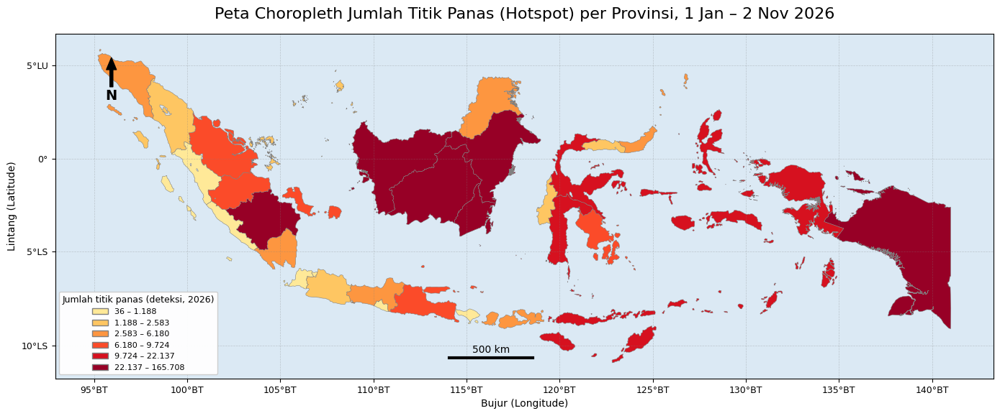

,Propinsi,Jumlah_titik,Luas_km2,Titik_per_1000km2
0,Kalimantan Tengah,165708,"155,381.95","1,066.46"
1,Papua,79937,"318,191.98",251.22
2,Kalimantan Barat,79447,"148,215.91",536.02
3,Sumatera Selatan,49933,"87,160.27",572.89
4,Kalimantan Timur,32726,"127,080.07",257.52
5,Kalimantan Selatan,26335,"37,109.02",709.67
6,Maluku,17939,"45,735.65",392.23
7,Papua Barat,15180,"95,426.73",159.07
8,Nusa Tenggara Timur,12746,"47,414.46",268.82
9,Sulawesi Tengah,11893,"59,921.20",198.48


In [32]:
# Catatan: menghitung jumlah titik panas per provinsi dari hasil spatial join (titik_api),
# lalu menggabungkannya ke peta provinsi untuk choropleth.
hitung = (titik_api.dropna(subset=['Propinsi'])
            .groupby('Propinsi').size().rename('Jumlah_titik'))

peta_titik = gpd.GeoDataFrame(
    peta[['Propinsi', 'Luas_km2', 'geometry']].merge(hitung, left_on='Propinsi', right_index=True, how='left'),
    geometry='geometry', crs=peta.crs)
peta_titik['Jumlah_titik'] = peta_titik['Jumlah_titik'].fillna(0).astype(int)
peta_titik['Titik_per_1000km2'] = peta_titik['Jumlah_titik'] / peta_titik['Luas_km2'] * 1000

print(f"Total titik panas yang masuk provinsi: {peta_titik['Jumlah_titik'].sum():,}".replace(',', '.'))
print(f"Provinsi tanpa titik panas: {int((peta_titik['Jumlah_titik'] == 0).sum())}")

cmap_c, norm_c, handles_c = skala_kelas(peta_titik['Jumlah_titik'], 'YlOrRd', k=6, desimal=0)
fig, ax = plt.subplots(figsize=(14, 7))
peta_titik.plot(column='Jumlah_titik', ax=ax, cmap=cmap_c, norm=norm_c, edgecolor='grey', linewidth=0.4)
ax.set_title('Peta Choropleth Jumlah Titik Panas (Hotspot) per Provinsi, 1 Jan – 2 Nov 2026',
             fontsize=16, pad=15)
tambah_koordinat(ax)
tambah_legenda(ax, handles_c, 'Jumlah titik panas (deteksi, 2026)')
tambah_elemen_peta(ax)
plt.tight_layout()
plt.savefig('peta_choropleth_jumlah_titik_panas_2026.png', dpi=300, bbox_inches='tight')
plt.show()

# 10 provinsi dengan jumlah titik terbanyak, beserta kepadatannya per 1.000 km²
peta_titik.sort_values('Jumlah_titik', ascending=False)[
    ['Propinsi', 'Jumlah_titik', 'Luas_km2', 'Titik_per_1000km2']].head(10).reset_index(drop=True)


In [33]:
# Ringkasan CRS yang dipakai di seluruh notebook
print("CRS batas provinsi (asli)    :", gdf.crs.to_string())
print("CRS analisis dan peta statis :", peta.crs.to_string())
print("CRS peta interaktif          : EPSG:4326 (WGS84)")
print("CRS titik panas (asli)       : EPSG:4326 (lat/lon dari FIRMS), diproyeksikan ke EPSG:3857")

CRS batas provinsi (asli)    : EPSG:4326
CRS analisis dan peta statis : EPSG:3857
CRS peta interaktif          : EPSG:4326 (WGS84)
CRS titik panas (asli)       : EPSG:4326 (lat/lon dari FIRMS), diproyeksikan ke EPSG:3857


---
## 15. Kesimpulan

In [34]:
# Catatan: seluruh angka dan urutan pada kesimpulan dihitung otomatis dari data.
periode = f"{kolom_tahun[0]}–{kolom_tahun[-1]}"

tot_per_tahun = peta[kolom_tahun].sum()          # total luas terbakar per tahun
total = tot_per_tahun.sum()

prov = peta.set_index('Propinsi')
luas_prov = prov[kolom_tahun].sum(axis=1).sort_values(ascending=False)   # luas akumulasi per provinsi
intens_prov = (luas_prov / prov['Luas_km2']).sort_values(ascending=False) # ha per km²

pulau_all = peta.groupby('Pulau')[kolom_tahun].sum().sum(axis=1).sort_values(ascending=False)
persen_pulau = pulau_all / pulau_all.sum() * 100

if set(intens_prov.index[:3]) == set(luas_prov.index[:3]):
    catatan_urutan = "Tiga provinsi teratas pada intensitas sama dengan tiga teratas pada luas absolut."
else:
    catatan_urutan = "Urutannya berbeda dari urutan luas absolut karena ukuran provinsi tidak sama."

baris = [
    f"1. **Seberapa besar:** selama {periode} total lahan yang terbakar mencapai {rp(total)} ha. "
    f"Tahun terparah adalah {tot_per_tahun.idxmax()} ({rp(tot_per_tahun.max())} ha) dan tahun terendah adalah "
    f"{tot_per_tahun.idxmin()} ({rp(tot_per_tahun.min())} ha), sehingga karhutla berfluktuasi cukup besar dari tahun ke tahun.",

    f"2. **Di mana:** secara akumulasi, kelompok pulau dengan karhutla terluas adalah {pulau_all.index[0]} "
    f"({persen_pulau.iloc[0]:.0f}%), {pulau_all.index[1]} ({persen_pulau.iloc[1]:.0f}%), dan "
    f"{pulau_all.index[2]} ({persen_pulau.iloc[2]:.0f}%). Provinsi dengan luas terbesar secara akumulasi adalah "
    f"{', '.join(luas_prov.index[:3])}.",

    f"3. **Seberapa parah bagi wilayahnya:** berdasarkan intensitas (luas terbakar per km² wilayah), provinsi "
    f"paling terdampak adalah {', '.join(intens_prov.index[:3])}. {catatan_urutan}",

    "4. **Makna bagi penanganan:** karhutla cenderung terpusat pada beberapa provinsi dan melonjak pada tahun "
    "tertentu, bukan merata sepanjang waktu. Pencegahan dan pemadaman akan lebih efektif jika difokuskan pada "
    "provinsi yang berulang kali menjadi yang terparah.",

    "5. **Fungsi tiap peta:** peta choropleth menunjukkan total lahan terbakar per provinsi, peta intensitas "
    "menunjukkan keparahan relatif terhadap luas wilayah, peta titik membandingkan besaran tanpa terpengaruh "
    "ukuran provinsi, dan peta interaktif memudahkan pembacaan angka tiap provinsi pada setiap tahun.",
]
display(Markdown('\n\n'.join(baris)))

1. **Seberapa besar:** selama 2018–2026 total lahan yang terbakar mencapai 4.791.463 ha. Tahun terparah adalah 2019 (1.649.258 ha) dan tahun terendah adalah 2025 (12.227 ha), sehingga karhutla berfluktuasi cukup besar dari tahun ke tahun.

2. **Di mana:** secara akumulasi, kelompok pulau dengan karhutla terluas adalah Kalimantan (34%), Bali & Nusa Tenggara (23%), dan Sumatera (21%). Provinsi dengan luas terbesar secara akumulasi adalah Nusa Tenggara Timur, Kalimantan Tengah, Sumatera Selatan.

3. **Seberapa parah bagi wilayahnya:** berdasarkan intensitas (luas terbakar per km² wilayah), provinsi paling terdampak adalah Nusa Tenggara Barat, Nusa Tenggara Timur, Kalimantan Selatan. Urutannya berbeda dari urutan luas absolut karena ukuran provinsi tidak sama.

4. **Makna bagi penanganan:** karhutla cenderung terpusat pada beberapa provinsi dan melonjak pada tahun tertentu, bukan merata sepanjang waktu. Pencegahan dan pemadaman akan lebih efektif jika difokuskan pada provinsi yang berulang kali menjadi yang terparah.

5. **Fungsi tiap peta:** peta choropleth menunjukkan total lahan terbakar per provinsi, peta intensitas menunjukkan keparahan relatif terhadap luas wilayah, peta titik membandingkan besaran tanpa terpengaruh ukuran provinsi, dan peta interaktif memudahkan pembacaan angka tiap provinsi pada setiap tahun.

### Catatan membaca peta
- Angka Papua dan Papua Barat mencakup provinsi pemekarannya (Papua Selatan, Papua Tengah, Papua Pegunungan, Papua Barat Daya) karena batas peta yang dipakai belum memuatnya.
- Titik pada peta titik (bagian 11 dan 12) berada di pusat provinsi dan menandai besaran karhutla provinsi tersebut, bukan lokasi api.
- Total tahun terakhir pada data dapat belum mencakup satu tahun penuh, sehingga perlu hati-hati saat dibandingkan dengan tahun lain.